# Segmentation d'images pour vehicule autonome

Projet 8 du parcours AI Engineer, OpenClassrooms.
Auteur : Dimitri Wyts.

## Le probleme

Future Vision Transport concoit un systeme embarque de vision par ordinateur pour
vehicules autonomes. Ce systeme se decoupe en quatre blocs : acquisition des images,
traitement des images, segmentation des images, systeme de decision.

Ma partie est la troisieme. Elle recoit une photo prise par la camera du vehicule et
doit produire un *masque de segmentation* : une image de meme taille ou chaque pixel
porte l'etiquette de ce qu'il represente. Le bloc de decision, en aval, se sert de ce
masque pour savoir ou est la route, ou sont les pietons et ou sont les autres vehicules.

On parle ici de **segmentation semantique**. C'est le fait de classer chaque pixel
individuellement dans une categorie. A distinguer de deux problemes voisins :

- la *classification d'image* repond a "qu'y a-t-il sur cette photo ?" et rend une
  seule etiquette pour toute l'image ;
- la *detection d'objets* rend des rectangles autour des objets, ce qui est trop
  grossier ici : un rectangle autour d'une route ne dit pas ou s'arrete le trottoir ;
- la *segmentation d'instances* distingue en plus les objets entre eux (voiture 1,
  voiture 2). C'est plus riche, mais le bloc de decision n'en a pas besoin, et ca
  couterait plus cher en calcul dans un systeme embarque.

La segmentation semantique est donc le bon niveau de granularite pour ce besoin.

## Les contraintes du projet

- **Keras** est impose, c'est le framework commun de l'equipe (contrainte de Franck,
  en charge du traitement des images en amont).
- Le resultat doit s'exposer via une **API** simple, consommee par Laura en aval.
- Seules les **8 categories principales** de Cityscapes sont demandees, pas les 32
  sous-categories.

## Ce que contient ce notebook

1. Configuration et reproductibilite
2. Exploration du jeu de donnees Cityscapes
3. Construction des jeux d'entrainement, de validation et de test
4. Mise en cache des images redimensionnees
5. Le generateur de donnees
6. Les metriques et les fonctions de cout
7. Les modeles compares
8. Entrainements et comparaison
9. Apport de l'augmentation de donnees
10. Evaluation finale et export du modele

---
# 1. Configuration et reproductibilite

## Pourquoi PyTorch apparait ici alors que la consigne impose Keras

Keras est une bibliotheque qui sert a decrire et entrainer des reseaux de neurones
avec un code lisible. Mais Keras ne calcule rien lui-meme : il a besoin d'un moteur
de calcul en dessous, ce qu'on appelle un *backend*.

Historiquement ce backend etait TensorFlow. Le probleme, c'est que TensorFlow a
abandonne le support de la carte graphique sous Windows a partir de sa version 2.11,
fin 2022. Installer TensorFlow aujourd'hui sur cette machine reviendrait a calculer
sur le processeur et a ignorer la carte graphique, soit des entrainements dix a vingt
fois plus lents.

Depuis sa version 3, Keras fonctionne au choix sur TensorFlow, PyTorch ou JAX. Le code
ecrit reste strictement du Keras, seul le moteur en dessous change. J'ai donc choisi
PyTorch comme backend, parce qu'il gere la carte graphique sous Windows sans aucune
installation manuelle de CUDA.

La contrainte de Franck est respectee a la lettre : tout le code de modelisation
ci-dessous est du Keras standard, relisible par n'importe qui dans l'equipe.

Le choix du backend doit etre fait **avant** le premier import de Keras, d'ou la
variable d'environnement en tete de cellule.

## Pourquoi fixer les graines aleatoires

Un entrainement de reseau de neurones fait intervenir du hasard a plusieurs endroits :
l'initialisation des poids, l'ordre de melange des images, les transformations
d'augmentation. Sans precaution, deux executions du meme code donnent deux resultats
differents, et on ne peut plus dire si un ecart entre deux modeles vient du modele ou
du hasard. Fixer la graine rend les tirages reproductibles.

In [1]:
import os

# doit etre defini avant le premier import de keras
os.environ["KERAS_BACKEND"] = "torch"

import json
import random
import time
from pathlib import Path

import keras
import numpy as np
import torch

# ---------------------------------------------------------------- graine unique
# une seule graine propagee partout, pour que tout soit reproductible
GRAINE = 42

random.seed(GRAINE)
np.random.seed(GRAINE)
torch.manual_seed(GRAINE)
torch.cuda.manual_seed_all(GRAINE)
keras.utils.set_random_seed(GRAINE)

# ------------------------------------------------------------------- chemins
# Les donnees brutes pesent pres de 8 Go : elles vivent hors du projet, pour ne
# se retrouver ni dans le depot ni dans l'archive a rendre. Elles sont sur un
# disque mecanique, ce qui est acceptable car on ne les lit qu'une seule fois.
DONNEES = Path(r"E:\cityscapes")
IMAGES = DONNEES / "leftImg8bit"   # les photos
MASQUES = DONNEES / "gtFine"       # les annotations

# Le cache, lui, est relu integralement a chaque passage d'entrainement, donc
# des dizaines de fois. Il est place sur le disque SSD de la machine, ou les
# lectures sont bien plus rapides. Il reste hors du dossier du projet.
CACHE = Path.home() / "projet8_cache"

SORTIES = Path("sorties")          # modeles entraines et resultats, dans le projet

CACHE.mkdir(exist_ok=True)
SORTIES.mkdir(exist_ok=True)

# ------------------------------------------------------------------- controle
print("keras  ", keras.__version__)
print("backend", keras.backend.backend())
print("torch  ", torch.__version__)
print("cuda    disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu    ", torch.cuda.get_device_name(0))
    print("memoire", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), "Go")

keras   3.15.1
backend torch
torch   2.11.0+cu128
cuda    disponible : True
gpu     NVIDIA GeForce RTX 3060
memoire 12.0 Go


---
# 2. Exploration du jeu de donnees

## Cityscapes en deux mots

Cityscapes est un jeu de donnees d'images de rues allemandes, filmees depuis une
voiture equipee d'une paire de cameras stereo. Il est devenu la reference pour la
segmentation semantique en conduite autonome, ce qui est exactement notre cas d'usage.

Il se decompose en deux archives :

- `leftImg8bit` : les photos elles-memes. Le nom signifie "image de la camera gauche,
  8 bits par canal". On n'utilise que l'image gauche de la paire stereo, la droite ne
  servirait qu'a calculer la profondeur, dont on n'a pas besoin ici.
- `gtFine` : les annotations, pour "ground truth, fine annotations", c'est-a-dire la
  verite terrain tracee finement a la main. C'est la reference contre laquelle on
  comparera les predictions.

Chaque image annotee est accompagnee de quatre fichiers, dont un seul nous interesse :

| fichier | contenu | utile ici |
|---|---|---|
| `labelIds.png` | un numero de classe par pixel | oui, c'est notre cible |
| `color.png` | le meme masque colorie en 32 sous-categories | non, on coloriera nous-memes en 8 |
| `instanceIds.png` | separe les objets individuels | non, c'est pour la segmentation d'instances |
| `polygons.json` | les contours bruts des annotateurs | non, deja convertis en `labelIds.png` |

Je n'ai donc extrait de l'archive que les 5000 fichiers `labelIds.png`, au lieu des
20 000 fichiers qu'elle contient.

In [2]:
# Inventaire de ce qu'on a reellement sur le disque.
# Le split "test" affiche 0 photo : je ne les ai volontairement pas extraites de
# l'archive. La cellule suivante montre pourquoi ce split est inexploitable, ca
# aurait fait 1525 images et 3 Go de disque pour rien.
for split in ("train", "val", "test"):
    photos = sorted((IMAGES / split).rglob("*_leftImg8bit.png"))
    masques = sorted((MASQUES / split).rglob("*_labelIds.png"))
    villes = sorted({p.parent.name for p in masques})
    print(f"{split:5s} : {len(photos):4d} photos | {len(masques):4d} masques | {len(villes):2d} villes")

train : 2975 photos | 2975 masques | 18 villes
val   :  500 photos |  500 masques |  3 villes
test  :    0 photos | 1525 masques |  6 villes


## Premier constat : le split `test` est inutilisable

Cityscapes fournit trois decoupages : `train`, `val` et `test`. Le reflexe serait
d'entrainer sur `train`, de regler sur `val` et de mesurer sur `test`.

Sauf que les organisateurs de Cityscapes gardent secretes les annotations du `test`,
pour alimenter un classement en ligne ou les equipes soumettent leurs predictions.
Les fichiers `labelIds.png` du `test` sont donc bien presents, mais vides.

Je ne le prends pas pour acquis, je le verifie sur les donnees.

In [3]:
from PIL import Image

# on regarde ce que contiennent vraiment les masques de chaque split
for split in ("train", "val", "test"):
    exemples = sorted((MASQUES / split).rglob("*_labelIds.png"))[:3]
    print(f"--- {split} ---")
    for f in exemples:
        masque = np.array(Image.open(f))
        valeurs, effectifs = np.unique(masque, return_counts=True)
        part = effectifs / effectifs.sum() * 100
        apercu = ", ".join(f"{v}:{p:.1f}%" for v, p in list(zip(valeurs, part))[:6])
        print(f"  {masque.shape} | {len(valeurs):2d} classes distinctes | {apercu}")

--- train ---


  (1024, 2048) | 16 classes distinctes | 0:0.0%, 1:3.9%, 3:1.5%, 4:0.7%, 7:39.6%, 8:1.4%
  (1024, 2048) | 18 classes distinctes | 0:0.0%, 1:3.9%, 3:1.5%, 4:1.0%, 5:0.0%, 6:1.4%
  (1024, 2048) | 19 classes distinctes | 0:0.0%, 1:3.9%, 3:1.5%, 4:0.8%, 5:0.0%, 6:0.1%
--- val ---
  (1024, 2048) | 14 classes distinctes | 1:5.8%, 2:3.5%, 3:1.5%, 4:0.7%, 7:29.8%, 8:8.0%
  (1024, 2048) | 16 classes distinctes | 1:5.8%, 2:3.5%, 3:1.5%, 4:0.0%, 7:34.6%, 8:1.9%


  (1024, 2048) | 14 classes distinctes | 1:5.8%, 2:3.5%, 3:1.5%, 4:0.1%, 7:33.6%, 8:2.3%
--- test ---


  (1024, 2048) |  3 classes distinctes | 0:94.6%, 1:3.9%, 3:1.5%


  (1024, 2048) |  3 classes distinctes | 0:94.6%, 1:3.9%, 3:1.5%
  (1024, 2048) |  3 classes distinctes | 0:94.6%, 1:3.9%, 3:1.5%


Le verdict est net. Les masques de `train` et `val` contiennent 14 a 19 classes
distinctes avec des proportions qui varient d'une image a l'autre. Ceux de `test` n'en
contiennent que trois, toujours dans les memes proportions : `unlabeled` a 94,6 %,
`ego vehicle` a 3,9 % (le capot de la voiture qui filme) et `rectification border` a
1,5 % (les bords deformes par la calibration des cameras). Aucune route, aucun batiment,
aucun pieton. C'est un masque generique recopie a l'identique sur les 1525 images.

**Consequence sur le protocole**, et c'est la decision la plus structurante du projet :

```
gtFine/train (2975 images) -> decoupe en entrainement + validation
gtFine/val   ( 500 images) -> devient notre jeu de test final
gtFine/test  (1525 images) -> mis de cote, inexploitable
```

Le jeu de validation servira a choisir l'architecture et les reglages. Les 500 images
de `val` ne seront ouvertes qu'une seule fois, tout a la fin, pour produire les chiffres
annonces dans la note technique. C'est la seule facon d'avoir une mesure honnete : des
qu'on regarde le jeu de test pour prendre une decision, il cesse d'etre un jeu de test.

## Des 34 classes aux 8 categories

Le fichier `labelIds.png` code 34 classes fines (route, trottoir, parking, rail,
batiment, mur, barriere...). La consigne demande de travailler sur les 8 categories
principales.

Bonne nouvelle : il n'y a rien a inventer. Les auteurs de Cityscapes definissent
eux-memes un regroupement officiel, dans le fichier `labels.py` de leur depot
`cityscapesScripts`. Chaque classe y porte un `catId`, l'identifiant de sa categorie.
J'ai repris cette table telle quelle plutot que d'inventer mon propre regroupement :
c'est verifiable, et ca evite de defendre un choix personnel discutable.

Une remarque sur la categorie `void`. Elle regroupe tout ce qui n'est pas annote :
le ciel derriere un obstacle, le capot de la voiture, les bords deformes. Cityscapes
la compte comme une des 8 categories, je la garde donc comme une classe a part entiere.
C'est aussi plus realiste : en production le modele doit bien predire quelque chose sur
ces pixels-la.

In [4]:
# regroupement officiel Cityscapes : classe fine (id) -> categorie (catId)
# source : cityscapesScripts/cityscapesscripts/helpers/labels.py
CATEGORIES = {
    0: ("void",         [0, 1, 2, 3, 4, 5, 6]),
    1: ("flat",         [7, 8, 9, 10]),
    2: ("construction", [11, 12, 13, 14, 15, 16]),
    3: ("object",       [17, 18, 19, 20]),
    4: ("nature",       [21, 22]),
    5: ("sky",          [23]),
    6: ("human",        [24, 25]),
    7: ("vehicle",      [26, 27, 28, 29, 30, 31, 32, 33]),
}

NOMS = [nom for nom, _ in CATEGORIES.values()]
NB_CLASSES = len(CATEGORIES)

# Table de correspondance : un tableau de 34 cases ou la case i contient la
# categorie de la classe fine i. Appliquee a un masque, elle le convertit d'un
# coup, sans boucle Python : TABLE[masque] suffit. C'est instantane meme sur une
# image de 2 millions de pixels, la ou une boucle prendrait plusieurs secondes.
TABLE = np.zeros(34, dtype=np.uint8)
for categorie, (nom, ids_fins) in CATEGORIES.items():
    TABLE[ids_fins] = categorie

# palette d'affichage : une couleur par categorie, reprise de la classe la plus
# representative de chaque groupe dans la palette officielle Cityscapes
PALETTE = np.array([
    (  0,   0,   0),   # void         noir
    (128,  64, 128),   # flat         violet (couleur officielle de la route)
    ( 70,  70,  70),   # construction gris   (couleur officielle des batiments)
    (250, 170,  30),   # object       orange (couleur officielle des feux)
    (107, 142,  35),   # nature       vert   (couleur officielle de la vegetation)
    ( 70, 130, 180),   # sky          bleu ciel
    (220,  20,  60),   # human        rouge  (couleur officielle des pietons)
    (  0,   0, 142),   # vehicle      bleu fonce (couleur officielle des voitures)
], dtype=np.uint8)

for categorie, (nom, ids_fins) in CATEGORIES.items():
    print(f"{categorie}  {nom:13s} <- ids {ids_fins}")

0  void          <- ids [0, 1, 2, 3, 4, 5, 6]
1  flat          <- ids [7, 8, 9, 10]
2  construction  <- ids [11, 12, 13, 14, 15, 16]
3  object        <- ids [17, 18, 19, 20]
4  nature        <- ids [21, 22]
5  sky           <- ids [23]
6  human         <- ids [24, 25]
7  vehicle       <- ids [26, 27, 28, 29, 30, 31, 32, 33]


In [5]:
# controle de securite : les masques ne doivent contenir que des valeurs de 0 a 33.
# La table officielle mentionne une classe "license plate" d'identifiant -1, qui est
# impossible a stocker dans un PNG 8 bits. Je verifie qu'elle n'apparait pas, sinon
# la table de correspondance planterait ou donnerait un resultat faux.
t0 = time.perf_counter()
valeurs_vues = set()
for split in ("train", "val"):
    for f in sorted((MASQUES / split).rglob("*_labelIds.png"))[:200]:
        valeurs_vues |= set(np.unique(np.array(Image.open(f))).tolist())

print("valeurs rencontrees :", sorted(valeurs_vues))
print("minimum", min(valeurs_vues), "| maximum", max(valeurs_vues))
print(f"verifie sur 400 masques en {time.perf_counter() - t0:.1f}s")

valeurs rencontrees : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
minimum 0 | maximum 33
verifie sur 400 masques en 4.4s


---
# 3. Construction des jeux d'entrainement, de validation et de test

## Pourquoi decouper par ville et pas au hasard

Il faut sortir un jeu de validation des 2975 images de `train`. Le reflexe serait de
tirer 15 % des images au hasard. Ce serait une erreur ici.

Cityscapes a ete filme depuis une voiture en mouvement. Deux images consecutives d'une
meme ville sont prises a quelques secondes d'intervalle : meme rue, meme meteo, meme
heure, souvent les memes batiments. Si je tire au hasard image par image, des scenes
quasi jumelles se retrouvent des deux cotes de la barriere. Le modele a donc
pratiquement deja vu l'image de validation pendant son entrainement, et le score de
validation devient artificiellement bon. C'est ce qu'on appelle une **fuite de donnees**.

En decoupant par ville entiere, aucune scene de validation n'a de sosie dans
l'entrainement. Et ca correspond au cas d'usage reel : le vehicule roulera dans des
villes qui n'etaient pas dans le jeu d'entrainement.

## Pourquoi tirer les villes au sort plutot que les choisir

Si je choisis moi-meme quelles villes mettre en validation, je peux, meme sans le
vouloir, prendre celles qui donnent les meilleurs scores. Un tirage avec une graine
fixee est reproductible, verifiable, et personne ne peut me soupconner de l'avoir
oriente.

## La regle d'arret, et pourquoi elle n'est pas evidente

Les villes sont tres inegales en taille. Empiler des villes tirees au sort jusqu'a
atteindre 15 % ne marche donc pas : si une grosse ville sort en dernier, la validation
deborde largement et on perd des images d'entrainement pour rien.

J'ajoute donc un plafond : on remplit jusqu'a 15 %, mais on saute toute ville qui
ferait depasser 18 %. La cellule de verification juste apres le tirage rejoue la regle
sur dix graines differentes, avec et sans plafond, pour montrer qu'elle est robuste et
pas taillee sur mesure pour la graine 42.

In [6]:
def lister(split):
    """Retourne la liste des couples (photo, masque) d'un split, triee.

    Le tri est important : sans lui, l'ordre depend du systeme de fichiers et
    le tirage aleatoire ne serait plus reproductible d'une machine a l'autre.
    """
    couples = []
    for masque in sorted((MASQUES / split).rglob("*_labelIds.png")):
        # aachen_000000_000019_gtFine_labelIds.png -> aachen_000000_000019_leftImg8bit.png
        base = masque.name.replace("_gtFine_labelIds.png", "")
        photo = IMAGES / split / masque.parent.name / f"{base}_leftImg8bit.png"
        couples.append((photo, masque))
    return couples


tous_train = lister("train")
test = lister("val")   # le "val" officiel devient notre jeu de test

# controle : chaque masque doit avoir sa photo
manquants = [p for p, _ in tous_train + test if not p.exists()]
print(f"train+val officiels : {len(tous_train) + len(test)} couples | photos manquantes : {len(manquants)}")

# --------------------------------------------- tirage des villes de validation
villes = sorted({m.parent.name for _, m in tous_train})
tailles = {v: sum(1 for _, m in tous_train if m.parent.name == v) for v in villes}

rng = np.random.default_rng(GRAINE)
melange = [villes[i] for i in rng.permutation(len(villes))]

# On empile des villes jusqu'a couvrir 15 % des images, en sautant celles qui
# feraient depasser 18 %. Le plafond est indispensable : les villes sont tres
# inegales, et sans lui une grosse ville tiree en dernier fait deborder la
# validation (la cellule suivante le montre sur dix graines).
OBJECTIF, PLAFOND = 0.15, 0.18
objectif = OBJECTIF * len(tous_train)

villes_val, cumul = [], 0
for ville in melange:
    if cumul >= objectif:
        break
    if cumul + tailles[ville] <= PLAFOND * len(tous_train):
        villes_val.append(ville)
        cumul += tailles[ville]

train = [c for c in tous_train if c[1].parent.name not in villes_val]
val = [c for c in tous_train if c[1].parent.name in villes_val]

print(f"\nvilles de validation tirees : {sorted(villes_val)}")
print(f"entrainement : {len(train):4d} images ({len(train)/len(tous_train)*100:.1f}%)")
print(f"validation   : {len(val):4d} images ({len(val)/len(tous_train)*100:.1f}%)")
print(f"test final   : {len(test):4d} images ({sorted({m.parent.name for _, m in test})})")

train+val officiels : 3475 couples | photos manquantes : 0

villes de validation tirees : ['erfurt', 'krefeld', 'weimar', 'zurich']
entrainement : 2503 images (84.1%)
validation   :  472 images (15.9%)
test final   :  500 images (['frankfurt', 'lindau', 'munster'])


In [7]:
# Verification de la regle de decoupe. On rejoue le tirage sur dix graines
# differentes, avec et sans plafond. Si la regle ne marchait que pour la
# graine 42, ce serait du bricolage et non une regle.
def part_validation(graine, avec_plafond):
    """Part des images envoyees en validation pour une graine donnee, en %."""
    ordre = [villes[i] for i in np.random.default_rng(graine).permutation(len(villes))]
    cumul = 0
    for ville in ordre:
        if cumul >= objectif:
            break
        if not avec_plafond or cumul + tailles[ville] <= PLAFOND * len(tous_train):
            cumul += tailles[ville]
    return cumul / len(tous_train) * 100


petite, grosse = min(tailles, key=tailles.get), max(tailles, key=tailles.get)
print(f"villes : de {tailles[petite]} images ({petite}) a {tailles[grosse]} images ({grosse})\n")

print(f"{'graine':>6s} | {'sans plafond':>12s} | {'avec plafond':>12s}")
print("-" * 38)
for graine in [GRAINE] + list(range(10)):
    print(f"{graine:6d} | {part_validation(graine, False):11.1f}% | "
          f"{part_validation(graine, True):11.1f}%")

avec = [part_validation(g, True) for g in range(10)]
sans = [part_validation(g, False) for g in range(10)]
print(f"\nsur les graines 0 a 9 : sans plafond de {min(sans):.1f} a {max(sans):.1f} %,"
      f" avec plafond de {min(avec):.1f} a {max(avec):.1f} %")

villes : de 85 images (darmstadt) a 365 images (strasbourg)

graine | sans plafond | avec plafond
--------------------------------------
    42 |        21.1% |        15.9%
     0 |        19.1% |        16.8%
     1 |        15.5% |        15.5%
     2 |        16.8% |        16.8%
     3 |        15.5% |        15.5%
     4 |        18.2% |        17.4%
     5 |        17.6% |        17.6%
     6 |        15.4% |        15.4%
     7 |        20.3% |        16.9%
     8 |        23.0% |        17.9%
     9 |        15.1% |        15.1%

sur les graines 0 a 9 : sans plafond de 15.1 a 23.0 %, avec plafond de 15.1 a 17.9 %


In [8]:
# On fige la composition des trois jeux dans un fichier. Si je relance le notebook
# dans six mois avec une autre version de numpy, le tirage pourrait changer et les
# chiffres de la note technique ne correspondraient plus. Ce fichier est la preuve
# de ce qui a reellement ete utilise.
composition = {
    "graine": GRAINE,
    "villes_validation": sorted(villes_val),
    "villes_entrainement": sorted(set(villes) - set(villes_val)),
    "villes_test": sorted({m.parent.name for _, m in test}),
    "tailles": {"train": len(train), "val": len(val), "test": len(test)},
}
(SORTIES / "composition_jeux.json").write_text(json.dumps(composition, indent=2), encoding="utf-8")
print(json.dumps(composition, indent=2))

{
  "graine": 42,
  "villes_validation": [
    "erfurt",
    "krefeld",
    "weimar",
    "zurich"
  ],
  "villes_entrainement": [
    "aachen",
    "bochum",
    "bremen",
    "cologne",
    "darmstadt",
    "dusseldorf",
    "hamburg",
    "hanover",
    "jena",
    "monchengladbach",
    "strasbourg",
    "stuttgart",
    "tubingen",
    "ulm"
  ],
  "villes_test": [
    "frankfurt",
    "lindau",
    "munster"
  ],
  "tailles": {
    "train": 2503,
    "val": 472,
    "test": 500
  }
}


## A quoi ressemblent les donnees

Avant d'entrainer quoi que ce soit, je regarde. Une photo, son masque en 34 classes
fines, et le meme masque une fois ramene a nos 8 categories.

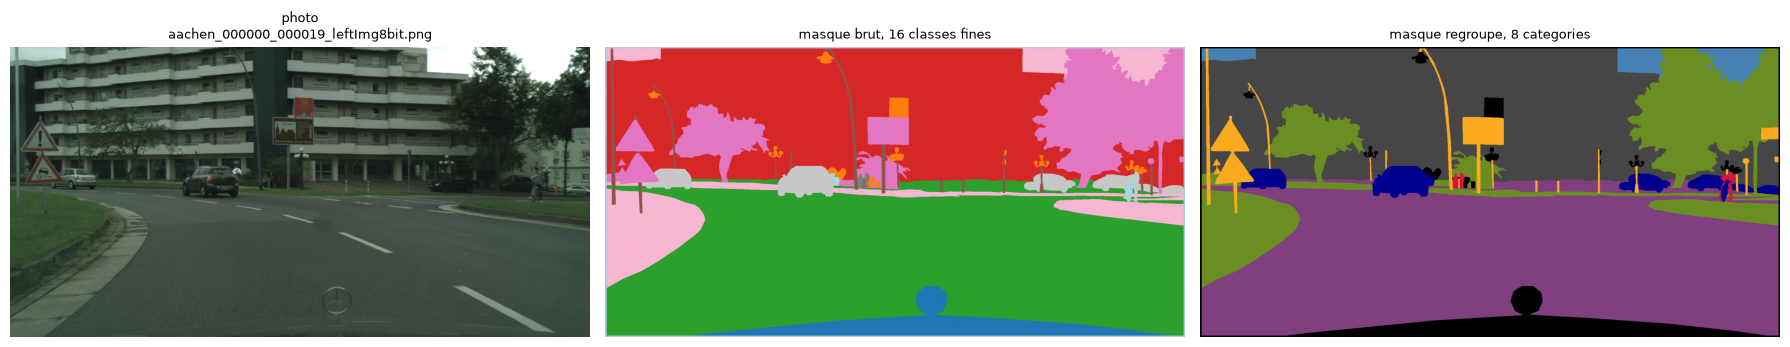

taille de la photo  : (1024, 2048, 3)
taille du masque    : (1024, 2048)
  void            6.1% de l'image
  flat           41.0% de l'image
  construction   29.2% de l'image
  object          2.8% de l'image
  nature         16.8% de l'image
  sky             1.8% de l'image
  human           0.2% de l'image
  vehicle         2.1% de l'image


In [9]:
import matplotlib.pyplot as plt

photo, masque = train[0]
img = np.array(Image.open(photo).convert("RGB"))
fin = np.array(Image.open(masque))
gros = TABLE[fin]   # la table de correspondance appliquee d'un coup

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(img)
axes[0].set_title(f"photo\n{photo.name}", fontsize=9)
axes[1].imshow(fin, cmap="tab20")
axes[1].set_title(f"masque brut, {len(np.unique(fin))} classes fines", fontsize=9)
axes[2].imshow(PALETTE[gros])
axes[2].set_title(f"masque regroupe, {len(np.unique(gros))} categories", fontsize=9)
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

print("taille de la photo  :", img.shape)
print("taille du masque    :", fin.shape)
for c in np.unique(gros):
    part = (gros == c).mean() * 100
    print(f"  {NOMS[c]:13s} {part:5.1f}% de l'image")

## Le desequilibre entre categories

Une image de rue est majoritairement faite de route, de batiments et de vegetation.
Les pietons et les panneaux n'occupent que quelques pour cent des pixels. Ce
desequilibre a une consequence directe sur le choix de la metrique : un modele qui
predirait "route" partout obtiendrait deja un pourcentage de pixels corrects flatteur,
tout en etant parfaitement inutile pour eviter un pieton.

Je mesure ce desequilibre sur un echantillon avant de choisir comment l'evaluer.

In [10]:
# On echantillonne plutot que de tout parcourir : 300 images suffisent pour
# estimer des proportions, et ca evite 10 minutes de lecture disque.
t0 = time.perf_counter()
taille_echantillon = min(300, len(train))
echantillon = [train[i] for i in rng.choice(len(train), size=taille_echantillon, replace=False)]

pixels_par_classe = np.zeros(NB_CLASSES, dtype=np.int64)
for _, masque in echantillon:
    gros = TABLE[np.array(Image.open(masque))]
    pixels_par_classe += np.bincount(gros.ravel(), minlength=NB_CLASSES)

part = pixels_par_classe / pixels_par_classe.sum() * 100
print(f"mesure sur {len(echantillon)} images en {time.perf_counter() - t0:.1f}s\n")
for c in np.argsort(-part):
    print(f"{NOMS[c]:13s} {part[c]:5.2f}%  {'#' * int(part[c] / 2)}")

mesure sur 300 images en 4.1s

flat          38.56%  ###################
construction  20.88%  ##########
nature        15.71%  #######
void          10.99%  #####
vehicle        7.23%  ###
sky            3.69%  #
object         1.77%  
human          1.17%  


---
# 4. Mise en cache des images redimensionnees

## Pourquoi un cache

Une image Cityscapes fait 2048x1024 pixels. La lire depuis le disque et la
redimensionner coute plusieurs dizaines de millisecondes (mesure dans la cellule
suivante). Un entrainement de 30 passages complets sur 2500 images represente 75 000
lectures, soit de l'ordre d'une heure passee uniquement a ouvrir des fichiers pendant
que la carte graphique attend sans rien faire.

Je redimensionne donc tout une fois pour toutes et je stocke le resultat dans un
fichier unique par jeu. Le generateur ira ensuite y piocher directement, en quelques
millisecondes.

## Quelle taille d'image

L'original est bien trop grand : une seule image en 2048x1024 avec 8 canaux de sortie
sature deja la memoire de la carte graphique des qu'on empile plusieurs images.

Je pars sur **512x256**, ce qui divise la surface par 16 tout en gardant le rapport
largeur/hauteur d'origine. Garder ce rapport evite d'ecraser les objets verticaux, ce
qui compte quand on cherche a reconnaitre des pietons et des poteaux.

## Le piege du redimensionnement des masques

Pour une photo, on utilise une interpolation lissee (bilineaire) : chaque pixel de
sortie est une moyenne ponderee des pixels voisins, ce qui donne un rendu propre.

Pour un masque, c'est interdit. Faire la moyenne entre un pixel de categorie 2
(construction) et un pixel de categorie 4 (nature) donnerait 3, soit "object". On
fabriquerait des annotations qui n'existent pas, en silence, sur toutes les frontieres
entre objets. Il faut donc la methode du **plus proche voisin**, qui recopie la valeur
du pixel source le plus proche sans jamais rien calculer.

In [11]:
import cv2

LARGEUR, HAUTEUR = 512, 256

# On chronometre sur 20 images avant de lancer les 3975. Si le temps par image
# est trop eleve, autant le savoir maintenant que dans 20 minutes.
t0 = time.perf_counter()
for photo, masque in train[:20]:
    img = cv2.imread(str(photo), cv2.IMREAD_COLOR)
    img = cv2.resize(img, (LARGEUR, HAUTEUR), interpolation=cv2.INTER_AREA)
    m = cv2.imread(str(masque), cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(TABLE[m], (LARGEUR, HAUTEUR), interpolation=cv2.INTER_NEAREST)
duree = time.perf_counter() - t0

par_image = duree / 20
total = len(train) + len(val) + len(test)
print(f"{par_image * 1000:.0f} ms par couple photo+masque")
print(f"estimation pour les {total} images : {par_image * total / 60:.1f} min en sequentiel")

43 ms par couple photo+masque
estimation pour les 3475 images : 2.5 min en sequentiel


## Le format du cache

Je stocke chaque jeu dans deux fichiers `.npy` : un pour les photos, un pour les
masques. C'est le format brut de numpy, sans compression, ce qui le rend instantane a
relire.

Ces fichiers sont ouverts en mode *memmap*. Au lieu de charger le fichier entier en
memoire, le systeme d'exploitation ne charge que les morceaux reellement lus. Le
generateur peut donc piocher un lot d'images sans jamais charger tout le jeu en
memoire. C'est exactement le comportement qu'on veut en production, ou on ne peut
jamais supposer que le jeu de donnees tient en memoire.

Le cache n'est pas ecrit a cote des donnees brutes, qui sont sur un disque mecanique,
mais sur le disque SSD de la machine : il est relu a chaque passage d'entrainement, il
doit donc etre sur le disque le plus rapide. Son poids exact est affiche par la cellule
de controle plus bas.

## Faut-il paralleliser la preparation ?

Le reflexe serait de lancer plusieurs threads pour lire les images en parallele. Je
mesure avant de decider. La cellule suivante fait le meme travail que la preparation du
cache (lire, redimensionner, convertir le masque), avec 1, 2, 4 puis 6 threads.

Chaque essai porte sur un groupe d'images different : si on relisait les memes, le
systeme d'exploitation les servirait depuis sa memoire et la mesure ne voudrait plus
rien dire.

In [12]:
from concurrent.futures import ThreadPoolExecutor


def lire_un_couple(couple):
    """Meme traitement que la preparation du cache, sans rien ecrire."""
    photo, masque = couple
    img = cv2.imread(str(photo), cv2.IMREAD_COLOR)
    cv2.resize(img, (LARGEUR, HAUTEUR), interpolation=cv2.INTER_AREA)
    m = TABLE[cv2.imread(str(masque), cv2.IMREAD_GRAYSCALE)]
    cv2.resize(m, (LARGEUR, HAUTEUR), interpolation=cv2.INTER_NEAREST)


N = 60          # images par essai
debut = 200     # loin des 20 images deja lues par le chronometrage plus haut
total = len(train) + len(val) + len(test)

print(f"{'threads':>7s} | {'par image':>9s} | {'estimation pour ' + str(total) + ' images':>27s}")
print("-" * 51)
for nb_threads in (1, 2, 4, 6):
    groupe = train[debut:debut + N]
    debut += N                      # un groupe different a chaque essai

    t0 = time.perf_counter()
    if nb_threads == 1:
        for couple in groupe:
            lire_un_couple(couple)
    else:
        with ThreadPoolExecutor(max_workers=nb_threads) as pool:
            list(pool.map(lire_un_couple, groupe))
    par_image = (time.perf_counter() - t0) / N

    print(f"{nb_threads:7d} | {par_image * 1000:6.0f} ms | {par_image * total / 60:23.1f} min")

threads | par image | estimation pour 3475 images
---------------------------------------------------


      1 |     44 ms |                     2.5 min


      2 |     22 ms |                     1.3 min


      4 |     12 ms |                     0.7 min


      6 |      9 ms |                     0.5 min


Ce resultat demande une lecture prudente. Sur cette execution, les threads accelerent
nettement la preparation. Mais ces images ont deja ete lues lors des executions
precedentes du notebook, et Windows garde en memoire les fichiers lus recemment : la
mesure porte alors sur le calcul (decodage et redimensionnement), qui se repartit bien
entre plusieurs coeurs, et presque plus sur le disque.

Lors de la toute premiere execution, avec des fichiers lus pour la premiere fois depuis
le disque dur mecanique, la tendance etait inverse : plusieurs threads qui reclament en
meme temps des fichiers eparpilles obligent la tete de lecture a sauter de l'un a
l'autre, et on perd plus en deplacements qu'on ne gagne en parallelisme.

Je garde donc une lecture sequentielle. La preparation ne se fait qu'une fois, elle
prend quelques minutes (estimation de la cellule precedente), et c'est le cas du disque
froid, celui ou les threads n'aident pas, qui compte pour une premiere preparation. La
lecon retenue : une mesure de lecture de fichiers depend de ce que le systeme a deja en
memoire, il faut savoir dans quel etat on mesure.


In [13]:
def preparer(jeu, nom):
    """Redimensionne un jeu complet et l'ecrit dans deux fichiers .npy.

    Lecture sequentielle : sur un disque mecanique lu a froid, paralleliser
    ralentit la preparation (voir l'explication au-dessus).
    """
    fichier_x = CACHE / f"{nom}_x_{LARGEUR}x{HAUTEUR}.npy"
    fichier_y = CACHE / f"{nom}_y_{LARGEUR}x{HAUTEUR}.npy"

    if fichier_x.exists() and fichier_y.exists():
        print(f"{nom:5s} : cache deja present, rien a faire")
        return fichier_x, fichier_y

    n = len(jeu)
    # open_memmap cree le fichier sur le disque et permet d'ecrire dedans
    # progressivement, sans jamais tout garder en memoire
    X = np.lib.format.open_memmap(fichier_x, mode="w+", dtype=np.uint8, shape=(n, HAUTEUR, LARGEUR, 3))
    Y = np.lib.format.open_memmap(fichier_y, mode="w+", dtype=np.uint8, shape=(n, HAUTEUR, LARGEUR))

    t0 = time.perf_counter()
    for i, (photo, masque) in enumerate(jeu):
        # INTER_AREA fait la moyenne des pixels sources : c'est la meilleure
        # methode quand on reduit une image, elle evite l'effet d'escalier
        img = cv2.imread(str(photo), cv2.IMREAD_COLOR)
        img = cv2.resize(img, (LARGEUR, HAUTEUR), interpolation=cv2.INTER_AREA)
        X[i] = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV lit en BGR, on repasse en RGB

        # INTER_NEAREST recopie la valeur du pixel le plus proche sans rien
        # calculer : indispensable pour ne pas inventer de categories
        m = TABLE[cv2.imread(str(masque), cv2.IMREAD_GRAYSCALE)]
        Y[i] = cv2.resize(m, (LARGEUR, HAUTEUR), interpolation=cv2.INTER_NEAREST)

        if (i + 1) % 500 == 0:
            print(f"  {nom} {i + 1}/{n} ... {time.perf_counter() - t0:.0f}s", flush=True)

    X.flush()
    Y.flush()
    duree = time.perf_counter() - t0
    poids = (fichier_x.stat().st_size + fichier_y.stat().st_size) / 1024**2
    print(f"{nom:5s} : {n:4d} images en {duree:5.1f}s ({duree / n * 1000:.0f} ms/image) | {poids:6.0f} Mo")
    return fichier_x, fichier_y


chemins_cache = {
    "train": preparer(train, "train"),
    "val": preparer(val, "val"),
    "test": preparer(test, "test"),
}

train : cache deja present, rien a faire
val   : cache deja present, rien a faire
test  : cache deja present, rien a faire


In [14]:
# Controle : on relit le cache et on verifie qu'il est coherent. Une erreur ici
# se propagerait silencieusement dans tous les entrainements.
for nom, (fx, fy) in chemins_cache.items():
    X = np.load(fx, mmap_mode="r")
    Y = np.load(fy, mmap_mode="r")
    classes = np.unique(Y[:50])
    print(f"{nom:5s} : X{X.shape} {X.dtype} | Y{Y.shape} {Y.dtype} | categories vues {classes}")
    assert X.shape[0] == Y.shape[0], "nombre d'images different entre photos et masques"
    assert classes.max() < NB_CLASSES, "categorie hors bornes dans le cache"
poids = sum(f.stat().st_size for paire in chemins_cache.values() for f in paire) / 1024**3
print(f"\ncache coherent | {poids:.2f} Go au total, dans {CACHE}")

train : X(2503, 256, 512, 3) uint8 | Y(2503, 256, 512) uint8 | categories vues [0 1 2 3 4 5 6 7]
val   : X(472, 256, 512, 3) uint8 | Y(472, 256, 512) uint8 | categories vues [0 1 2 3 4 5 6 7]
test  : X(500, 256, 512, 3) uint8 | Y(500, 256, 512) uint8 | categories vues [0 1 2 3 4 5 6 7]

cache coherent | 1.70 Go au total, dans C:\Users\wytsd\projet8_cache


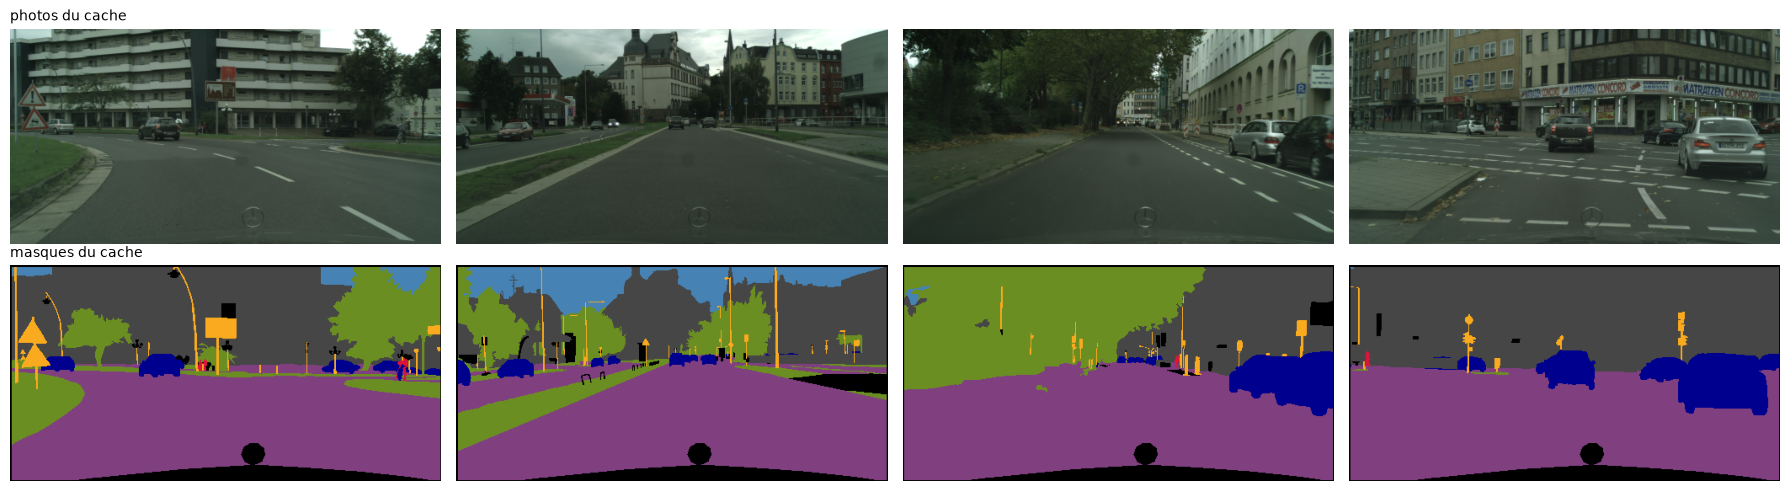

In [15]:
# verification visuelle : le cache doit ressembler aux images d'origine
X = np.load(chemins_cache["train"][0], mmap_mode="r")
Y = np.load(chemins_cache["train"][1], mmap_mode="r")

fig, axes = plt.subplots(2, 4, figsize=(18, 5))
for k in range(4):
    axes[0, k].imshow(X[k])
    axes[0, k].axis("off")
    axes[1, k].imshow(PALETTE[Y[k]])
    axes[1, k].axis("off")
axes[0, 0].set_title("photos du cache", loc="left", fontsize=10)
axes[1, 0].set_title("masques du cache", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

---
# 5. Le generateur de donnees

## A quoi sert un generateur

Un generateur fournit les images au modele par petits paquets, appeles *lots* ou
*batches*, au lieu de tout charger d'un coup. Trois raisons a ca :

1. **La memoire.** Meme si notre cache tiendrait en memoire, un jeu de donnees reel de
   plusieurs centaines de milliers d'images ne tiendrait jamais en RAM. Ecrire un
   generateur des maintenant, c'est ecrire un code qui passera a l'echelle sans
   reecriture. C'est ce que la consigne appelle le caractere industrialisable.
2. **L'augmentation de donnees.** Les transformations aleatoires doivent etre
   appliquees a la volee, differemment a chaque passage, pas figees une fois pour
   toutes sur le disque.
3. **Le melange.** Remelanger l'ordre des images a chaque passage evite que le modele
   apprenne l'ordre du jeu de donnees plutot que son contenu.

## Comment il est fait

Keras fournit une classe de base, `PyDataset`, dont il suffit de definir trois
methodes : combien de lots au total, comment fabriquer le lot numero i, et quoi faire
a la fin de chaque passage. Keras se charge du reste.

Une precision, verifiee dans le code de Keras et pas supposee : avec les reglages par
defaut, un seul *worker* et pas de multiprocessus, Keras fabrique chaque lot au moment
ou la carte le reclame, sans rien preparer a l'avance. On pourrait lui demander de
preparer les lots dans plusieurs threads, mais les tirages aleatoires de l'augmentation
se feraient alors dans un ordre imprevisible, et l'entrainement ne serait plus
reproductible. Je garde donc un seul worker, et je mesure juste apres ce que coute la
fabrication d'un lot.

## L'augmentation de donnees

Augmenter les donnees, c'est montrer au modele des variantes deformees des memes
images pour qu'il apprenne ce qui compte vraiment et pas les details de chaque photo.
Le choix des transformations n'est pas anodin ici :

- **Symetrie horizontale** : une rue vue en miroir reste une rue plausible. Utile,
  double virtuellement le jeu.
- **Luminosite et contraste** : le vehicule roulera par temps couvert, en plein soleil,
  au crepuscule. Tres pertinent pour notre cas d'usage.
- **Decalages et zooms legers** : la camera ne sera jamais exactement au meme endroit.
- **Symetrie verticale** : exclue. Une rue a l'envers n'existe pas, on apprendrait au
  modele une situation qu'il ne rencontrera jamais.
- **Rotations importantes** : exclues pour la meme raison.

Point critique : la transformation doit s'appliquer **exactement de la meme facon** a
la photo et a son masque. Si on retourne la photo sans retourner le masque, on
apprendrait au modele que la route est a droite alors qu'elle est a gauche. La
bibliotheque Albumentations gere ca nativement, c'est la raison pour laquelle je
l'utilise plutot que les outils generiques de Keras.

Un piege, lui aussi verifie dans le code de la bibliotheque : Albumentations utilise son
propre generateur aleatoire, totalement independant des graines fixees en tete de
notebook. Sans graine donnee explicitement, il tire des transformations differentes a
chaque execution. Je lui donne donc la sienne.

In [16]:
import albumentations as A

# transformations appliquees uniquement a l'entrainement
AUGMENTATION = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.5),
    A.Affine(
        translate_percent=(-0.05, 0.05),   # decalage de 5 % maximum
        scale=(0.9, 1.15),                 # zoom entre -10 % et +15 %
        rotate=(-8, 8),                    # rotation faible, l'horizon reste horizontal
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,                            # les bords vides sont noirs
        fill_mask=0,                       # et etiquetes "void", ce qui est correct
        p=0.5,
    ),
], seed=GRAINE)   # sa propre graine : les graines globales n'ont aucun effet sur lui


class GenerateurCityscapes(keras.utils.PyDataset):
    """Fournit les images du cache par lots, avec melange et augmentation optionnels."""

    def __init__(self, fichier_x, fichier_y, taille_lot=8, melanger=False,
                 augmentation=None, **kwargs):
        super().__init__(**kwargs)
        # mmap_mode="r" : le fichier reste sur le disque, seules les images
        # reellement demandees remontent en memoire
        self.X = np.load(fichier_x, mmap_mode="r")
        self.Y = np.load(fichier_y, mmap_mode="r")
        self.taille_lot = taille_lot
        self.melanger = melanger
        self.augmentation = augmentation

        # chaque generateur a son propre tirage, pour rester reproductible meme
        # si on en cree plusieurs
        self.rng = np.random.default_rng(GRAINE)
        self.ordre = np.arange(len(self.X))
        if self.melanger:
            self.rng.shuffle(self.ordre)

    def __len__(self):
        """Nombre de lots dans un passage complet."""
        return int(np.ceil(len(self.X) / self.taille_lot))

    def __getitem__(self, i):
        """Fabrique le lot numero i."""
        indices = self.ordre[i * self.taille_lot:(i + 1) * self.taille_lot]

        images = np.empty((len(indices), HAUTEUR, LARGEUR, 3), dtype=np.float32)
        masques = np.empty((len(indices), HAUTEUR, LARGEUR), dtype=np.int32)

        for k, idx in enumerate(indices):
            img = self.X[idx]
            msk = self.Y[idx]

            if self.augmentation is not None:
                # Albumentations applique la meme transformation geometrique a
                # l'image et au masque, c'est tout l'interet
                res = self.augmentation(image=np.asarray(img), mask=np.asarray(msk))
                img, msk = res["image"], res["mask"]

            # on ramene les valeurs de 0-255 a 0-1 : les reseaux convergent mal
            # sur des entrees de grande amplitude
            images[k] = img.astype(np.float32) / 255.0
            masques[k] = msk

        return images, masques

    def on_epoch_end(self):
        """Appelee par Keras a la fin de chaque passage sur le jeu."""
        if self.melanger:
            self.rng.shuffle(self.ordre)

In [17]:
# On verifie le generateur avant de s'en servir, et on chronometre la fabrication
# d'un lot, avec et sans augmentation.
gen_sans = GenerateurCityscapes(*chemins_cache["train"], taille_lot=8, melanger=True)
gen_test = GenerateurCityscapes(*chemins_cache["train"], taille_lot=8,
                                melanger=True, augmentation=AUGMENTATION)

# Les deux generateurs melangent avec la meme graine, donc lisent les memes images
# dans le meme ordre. On les lit d'abord une fois sans chronometrer : sinon le
# second chronometrage profiterait des images deja mises en memoire par le
# premier, et on comparerait surtout le cache du systeme, pas l'augmentation.
for i in range(11):
    gen_sans[i]

for gen, nom in ((gen_sans, "sans augmentation"), (gen_test, "avec augmentation")):
    t0 = time.perf_counter()
    for i in range(1, 11):
        gen[i]
    print(f"{nom:18s} : {(time.perf_counter() - t0) / 10 * 1000:5.0f} ms par lot de 8")

images, masques = gen_test[0]
print(f"\nlots par passage : {len(gen_test)}")
print(f"images : {images.shape} {images.dtype} | min {images.min():.2f} max {images.max():.2f}")
print(f"masques: {masques.shape} {masques.dtype} | categories {np.unique(masques)}")

sans augmentation  :     8 ms par lot de 8
avec augmentation  :    11 ms par lot de 8

lots par passage : 313
images : (8, 256, 512, 3) float32 | min 0.00 max 1.00
masques: (8, 256, 512) int32 | categories [0 1 2 3 4 5 6 7]


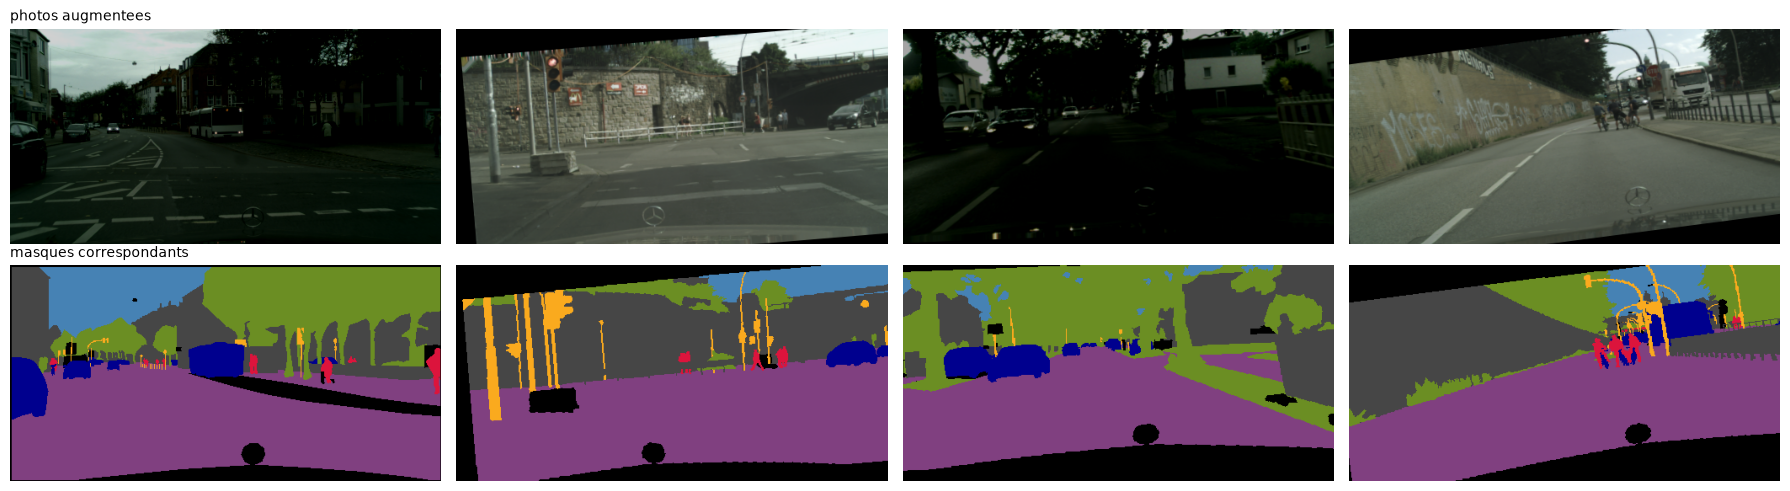

In [18]:
# controle visuel de l'augmentation : la photo et son masque doivent subir
# exactement la meme deformation, sinon tout l'entrainement est fausse
fig, axes = plt.subplots(2, 4, figsize=(18, 5))
for k in range(4):
    axes[0, k].imshow(images[k])
    axes[0, k].axis("off")
    axes[1, k].imshow(PALETTE[masques[k]])
    axes[1, k].axis("off")
axes[0, 0].set_title("photos augmentees", loc="left", fontsize=10)
axes[1, 0].set_title("masques correspondants", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

---
# 6. Comment mesurer la qualite d'une segmentation

## Pourquoi le pourcentage de pixels corrects ne suffit pas

La mesure la plus naturelle serait le pourcentage de pixels bien classes. Elle est
trompeuse ici, et la distribution mesuree plus haut explique pourquoi : la route et
les batiments occupent a eux seuls pres de 60 % des pixels, tandis que les humains n'en
representent que 1,17 %.

Un modele qui ignorerait completement les pietons, en les classant comme du bitume,
perdrait moins de 2 points sur cette mesure. Il afficherait un score flatteur tout en
etant inutilisable : c'est precisement le pieton que le systeme de decision doit voir.

## L'Intersection sur Union

La mesure de reference en segmentation est l'IoU, pour *Intersection over Union*. Pour
une categorie donnee, on compare deux zones : celle que le modele a predite, et celle
qui est reellement de cette categorie. L'IoU est la surface commune aux deux, divisee
par la surface totale que les deux couvrent ensemble.

```
        surface predite ET reelle
IoU = ------------------------------
        surface predite OU reelle
```

Elle vaut 1 quand les deux zones coincident parfaitement, et 0 quand elles ne se
touchent pas. Son interet par rapport au pourcentage de pixels : elle penalise a la
fois le fait de rater des pixels de la categorie, et le fait d'en inventer ailleurs.

## La moyenne sur les categories

On calcule ensuite la moyenne des IoU sur les 8 categories, ce qu'on note **mIoU**
pour *mean IoU*. Le point cle est qu'on ne pondere pas par la taille des categories :
l'IoU des humains compte autant que celui de la route, alors que les premiers sont
plus de trente fois moins nombreux en pixels.

C'est exactement le comportement voulu pour de la conduite autonome, et c'est aussi la
metrique officielle du classement Cityscapes, donc nos chiffres seront comparables a
la litterature.

## Un detail qui compte : les categories absentes

Toutes les categories ne sont pas presentes sur chaque image. Une rue sans piste
cyclable n'a aucun pixel de certaines sous-categories. Si une categorie absente
comptait comme un IoU de zero, la moyenne serait tiree vers le bas sans raison. On ne
retient donc que les categories effectivement presentes ou predites.

De la meme facon, on accumule les comptages sur tout le jeu de validation avant de
calculer le score, plutot que de moyenner des scores calcules image par image. Sinon
une image sans pieton ferait varier la moyenne au hasard.

## La metrique de Keras est inutilisable ici

Keras fournit `keras.metrics.MeanIoU`. Je l'ai essayee, et elle s'ecroule des que les
images grandissent. La cellule suivante le mesure. Attention, elle prend une trentaine
de secondes a cause de la version Keras, c'est justement ce qu'on veut montrer.

Je ne monte volontairement pas jusqu'a notre taille reelle de 512x256 : au rythme
constate, une seule mesure prendrait plusieurs minutes.

In [19]:
import torch
from keras import ops   # les operations de Keras, valables quel que soit le backend

# On mesure la version de Keras sur des tailles croissantes, mais on s'arrete
# avant notre taille reelle : elle deviendrait trop lente pour ce notebook.
print("keras.metrics.MeanIoU")
mesures = {}
for h, w in ((32, 64), (64, 128)):
    v = np.random.randint(0, NB_CLASSES, (8, h, w)).astype("int32")
    p = np.random.rand(8, h, w, NB_CLASSES).astype("float32")

    m = keras.metrics.MeanIoU(num_classes=NB_CLASSES, sparse_y_true=True, sparse_y_pred=False)
    t0 = time.perf_counter()
    m.update_state(v, p)
    mesures[8 * h * w] = time.perf_counter() - t0
    print(f"  {h}x{w:<4} ({8 * h * w:>9,d} pixels) : {mesures[8 * h * w]:7.2f} s par lot")

# Ordre de grandeur a notre taille reelle, en supposant simplement le cout
# proportionnel au nombre de pixels. C'est une extrapolation, pas une mesure :
# elle sert a juger si la metrique est utilisable, pas a donner un chiffre exact.
pixels_mesures, duree_mesuree = max(mesures.items())
pixels_reels = 8 * HAUTEUR * LARGEUR
par_lot = duree_mesuree * pixels_reels / pixels_mesures
lots_par_passage = int(np.ceil(len(train) / 6))      # lots de 6, la taille retenue plus loin
print(f"\nextrapole a un lot reel de 8 images en {LARGEUR}x{HAUTEUR} : environ {par_lot:.0f} s")
print(f"soit environ {par_lot * lots_par_passage / 3600:.0f} heures par passage d'entrainement,"
      f" rien que pour la metrique")

keras.metrics.MeanIoU


  32x64   (   16,384 pixels) :    1.80 s par lot


  64x128  (   65,536 pixels) :    7.17 s par lot

extrapole a un lot reel de 8 images en 512x256 : environ 115 s
soit environ 13 heures par passage d'entrainement, rien que pour la metrique


Plusieurs secondes pour un lot de huit images minuscules, et l'extrapolation a notre
taille reelle se compte en heures par passage d'entrainement, rien que pour mesurer la
performance, pendant que la carte graphique attendrait.

Je la reecris donc. L'astuce tient en une ligne : au lieu de comparer les categories
deux a deux, on encode chaque couple (categorie reelle, categorie predite) en un seul
nombre entier, et on compte les occurrences en une passe. Le cout devient proportionnel
au nombre de pixels, au lieu d'etre multiplie par le carre du nombre de categories.

In [20]:
class MoyenneIoU(keras.metrics.Metric):
    """Intersection sur Union moyennee sur les categories.

    On accumule une matrice de confusion lot par lot, et le score n'est calcule
    qu'a la fin du passage. C'est plus juste que de moyenner des scores calcules
    image par image : une categorie absente d'une image ne vient pas polluer la
    moyenne.
    """

    def __init__(self, nb_classes=NB_CLASSES, name="miou", **kwargs):
        super().__init__(name=name, **kwargs)
        self.nb_classes = nb_classes
        self.matrice = self.add_variable(
            shape=(nb_classes, nb_classes), initializer="zeros", name="matrice"
        )

    def update_state(self, y_vrai, y_pred, sample_weight=None):
        # y_pred arrive en probabilites (lot, hauteur, largeur, categorie) :
        # on retient la categorie la plus probable pour chaque pixel
        if len(y_pred.shape) == len(y_vrai.shape) + 1:
            y_pred = ops.argmax(y_pred, axis=-1)

        y_vrai = ops.cast(ops.reshape(y_vrai, [-1]), "int32")
        y_pred = ops.cast(ops.reshape(y_pred, [-1]), "int32")

        # comptage en une passe : le couple (vrai, predit) devient un seul entier
        codes = y_vrai * self.nb_classes + y_pred
        comptes = ops.bincount(codes, minlength=self.nb_classes ** 2)
        comptes = ops.reshape(comptes[: self.nb_classes ** 2],
                              (self.nb_classes, self.nb_classes))

        self.matrice.assign(self.matrice + ops.cast(comptes, self.matrice.dtype))

    def result(self):
        vrais_positifs = ops.diagonal(self.matrice)
        reels = ops.sum(self.matrice, axis=1)      # pixels vraiment de cette categorie
        predits = ops.sum(self.matrice, axis=0)    # pixels que le modele y a mis
        union = reels + predits - vrais_positifs

        iou = ops.divide_no_nan(vrais_positifs, union)

        # une categorie totalement absente ne doit pas compter comme un zero,
        # elle tirerait la moyenne vers le bas sans raison
        retenues = ops.cast(union > 0, "float32")
        return ops.divide_no_nan(ops.sum(iou * retenues), ops.sum(retenues))

    def iou_par_classe(self):
        """Le detail categorie par categorie, pour analyser les resultats."""
        vp = ops.diagonal(self.matrice)
        union = ops.sum(self.matrice, axis=1) + ops.sum(self.matrice, axis=0) - vp
        return ops.convert_to_numpy(ops.divide_no_nan(vp, union))

    def matrice_confusion(self):
        """Pour voir quelles categories le modele confond entre elles."""
        return ops.convert_to_numpy(self.matrice)

    def reset_state(self):
        self.matrice.assign(ops.zeros((self.nb_classes, self.nb_classes)))

## Verifier que la metrique dit vrai

Une metrique fausse ne se voit pas : elle affiche un nombre plausible et on choisit le
mauvais modele sans jamais s'en apercevoir. Je la confronte donc a un calcul de
reference ecrit differemment, en numpy pur, sur trois cas dont je connais la reponse.

In [21]:
def miou_reference(vrai, pred_classes):
    """Calcul de reference en numpy, lent mais independant de notre code."""
    matrice = np.zeros((NB_CLASSES, NB_CLASSES), dtype=np.int64)
    np.add.at(matrice, (vrai.ravel(), pred_classes.ravel()), 1)
    tp = np.diag(matrice)
    union = matrice.sum(1) + matrice.sum(0) - tp
    return np.nanmean(np.where(union > 0, tp / np.maximum(union, 1), np.nan))


tirage = np.random.default_rng(GRAINE)
vrai = tirage.integers(0, NB_CLASSES, (4, 64, 128)).astype("int32")

cas = {
    "prediction parfaite": np.eye(NB_CLASSES, dtype="float32")[vrai],
    "prediction aleatoire": tirage.random((*vrai.shape, NB_CLASSES)).astype("float32"),
    "tout en categorie flat": np.eye(NB_CLASSES, dtype="float32")[np.ones_like(vrai)],
}

for nom, pred in cas.items():
    m = MoyenneIoU()
    m.update_state(vrai, pred)
    obtenu, attendu = float(m.result()), miou_reference(vrai, pred.argmax(-1))
    etat = "OK" if abs(obtenu - attendu) < 1e-5 else "ECART"
    print(f"{nom:24s} : maison {obtenu:.6f} | reference {attendu:.6f} | {etat}")

prediction parfaite      : maison 1.000000 | reference 1.000000 | OK
prediction aleatoire     : maison 0.067916 | reference 0.067916 | OK
tout en categorie flat   : maison 0.015930 | reference 0.015930 | OK


In [22]:
# Deuxieme verification, tout aussi importante : la metrique doit donner le meme
# resultat qu'on lui passe les donnees d'un coup ou lot par lot. Pendant
# l'entrainement elle les recevra forcement par lots.
pred = cas["prediction aleatoire"]

m = MoyenneIoU()
m.update_state(vrai, pred)
en_une_fois = float(m.result())

m.reset_state()
for k in range(len(vrai)):
    m.update_state(vrai[k:k + 1], pred[k:k + 1])
en_plusieurs_lots = float(m.result())

print(f"en une fois        : {en_une_fois:.6f}")
print(f"en {len(vrai)} lots successifs : {en_plusieurs_lots:.6f}")
print(f"ecart              : {abs(en_une_fois - en_plusieurs_lots):.8f}")

en une fois        : 0.067916
en 4 lots successifs : 0.067916
ecart              : 0.00000000


In [23]:
# Et le cout de calcul, la ou la version de Keras s'ecroulait
print("MoyenneIoU (version maison)")
for h, w in ((32, 64), (64, 128), (256, 512)):
    v = ops.convert_to_tensor(tirage.integers(0, NB_CLASSES, (8, h, w)).astype("int32"))
    p = ops.convert_to_tensor(tirage.random((8, h, w, NB_CLASSES)).astype("float32"))

    m = MoyenneIoU()
    m.update_state(v, p)          # premier appel, mise en route comprise
    torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(10):
        m.update_state(v, p)
    torch.cuda.synchronize()
    duree = (time.perf_counter() - t0) / 10
    print(f"  {h}x{w:<4} ({8 * h * w:>9,d} pixels) : {duree * 1000:7.2f} ms par lot")

MoyenneIoU (version maison)


  32x64   (   16,384 pixels) :   11.80 ms par lot
  64x128  (   65,536 pixels) :    0.49 ms par lot


  256x512  (1,048,576 pixels) :    0.94 ms par lot

---
# 7. Les fonctions de cout

## Metrique et fonction de cout, ce n'est pas la meme chose

La metrique sert a nous, humains, pour comparer des modeles. La fonction de cout sert
au modele : c'est le nombre qu'il cherche a faire baisser, et c'est en la derivant
qu'on obtient la direction dans laquelle corriger chaque poids du reseau.

On ne peut pas toujours optimiser directement la metrique : le mIoU passe par un
`argmax`, une operation en escalier dont la derivee est nulle partout. Il ne donne donc
aucune indication de direction. Il faut une fonction de cout continue.

## L'entropie croisee, et sa limite ici

L'entropie croisee est le choix standard. Elle mesure a quel point le modele est sur de
la bonne reponse : elle vaut zero s'il met toute sa probabilite sur la bonne categorie,
et grimpe vite s'il se trompe avec assurance.

Son defaut dans notre cas est le meme que celui du pourcentage de pixels corrects :
elle traite chaque pixel a poids egal. Comme la route occupe vingt fois plus de pixels
que les humains, le modele fait baisser la perte plus efficacement en soignant la route
qu'en apprenant a voir les pietons.

## Le Dice, qui corrige ce biais

Le coefficient de Dice mesure lui aussi un recouvrement, comme l'IoU, mais avec une
formule legerement differente qui reste derivable. Surtout, il se calcule categorie par
categorie et chaque categorie pese pareil, quelle que soit sa surface.

C'est exactement le correctif qui manque a l'entropie croisee. En pratique on utilise
souvent la somme des deux : l'entropie donne un gradient net et guide bien au
demarrage, le Dice corrige le biais vers les grandes categories. C'est la combinaison
standard en imagerie medicale et satellitaire, ou le desequilibre entre classes est la
regle plutot que l'exception.

## Un obstacle technique : la fonction de Keras ne marche pas

`keras.losses.sparse_categorical_crossentropy` est concue pour exactement notre cas,
des cibles en entiers plutot qu'en vecteurs. Mais elle plante avec le backend PyTorch
des que la cible est une image de categories plutot qu'une etiquette unique.

La cellule suivante le montre, puis je donne ma version.

In [24]:
# Demonstration du probleme, dans un petit modele jetable
essai = keras.Sequential([
    keras.Input((64, 128, 3)),
    keras.layers.Conv2D(NB_CLASSES, 3, padding="same", activation="softmax"),
])
x_essai = np.random.rand(2, 64, 128, 3).astype("float32")
y_essai = np.random.randint(0, NB_CLASSES, (2, 64, 128)).astype("int32")

essai.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
try:
    essai.train_on_batch(x_essai, y_essai)
    print("la fonction de Keras fonctionne")
except Exception as e:
    print(f"la fonction de Keras echoue : {type(e).__name__}")
    print(f"  {e}")

la fonction de Keras echoue : RuntimeError


  grad_input must be contiguous


In [25]:
EPSILON = 1e-7


def entropie_croisee(y_vrai, y_pred):
    """Entropie croisee pour des cibles entieres.

    On convertit la cible en vecteurs a l'interieur de la fonction, directement
    sur la carte graphique. Le generateur peut ainsi continuer a fournir des
    entiers, huit fois plus legers que des vecteurs a huit composantes.

    Le decoupage des probabilites evite log(0), qui vaudrait moins l'infini et
    ferait exploser l'entrainement des qu'une probabilite tombe a zero.
    """
    y_vrai_oh = ops.one_hot(ops.cast(y_vrai, "int32"), NB_CLASSES)
    y_pred = ops.clip(y_pred, EPSILON, 1.0 - EPSILON)
    return ops.mean(-ops.sum(y_vrai_oh * ops.log(y_pred), axis=-1))


def perte_dice(y_vrai, y_pred, lissage=1.0):
    """1 moins le coefficient de Dice, moyenne sur les categories.

    Le lissage evite une division par zero quand une categorie est absente de
    l'image et non predite : le Dice vaut alors 1, donc la perte vaut 0, ce qui
    est le comportement voulu (rien a trouver, rien trouve, aucune erreur).
    """
    y_vrai_oh = ops.one_hot(ops.cast(y_vrai, "int32"), NB_CLASSES)

    axes = (0, 1, 2)   # on somme sur le lot, la hauteur et la largeur
    intersection = ops.sum(y_vrai_oh * y_pred, axis=axes)
    volumes = ops.sum(y_vrai_oh, axis=axes) + ops.sum(y_pred, axis=axes)

    return 1.0 - ops.mean((2.0 * intersection + lissage) / (volumes + lissage))


def entropie_et_dice(y_vrai, y_pred):
    """La somme des deux, pour cumuler leurs avantages."""
    return entropie_croisee(y_vrai, y_pred) + perte_dice(y_vrai, y_pred)

In [26]:
# On verifie les valeurs contre un calcul de reference ecrit differemment
def entropie_reference(v, p):
    p = np.clip(p, EPSILON, 1 - EPSILON)
    return -np.log(np.take_along_axis(p, v[..., None], -1)).mean()


def dice_reference(v, p, lissage=1.0):
    oh = np.eye(NB_CLASSES, dtype="float32")[v]
    inter = (oh * p).sum((0, 1, 2))
    vol = oh.sum((0, 1, 2)) + p.sum((0, 1, 2))
    return 1.0 - ((2 * inter + lissage) / (vol + lissage)).mean()


petit_vrai = tirage.integers(0, NB_CLASSES, (2, 16, 32)).astype("int32")
alea = tirage.random((*petit_vrai.shape, NB_CLASSES)).astype("float32")
alea /= alea.sum(-1, keepdims=True)

for nom, p in (("parfaite", np.eye(NB_CLASSES, dtype="float32")[petit_vrai]),
               ("aleatoire", alea)):
    tv, tp = ops.convert_to_tensor(petit_vrai), ops.convert_to_tensor(p)
    e_obt, e_ref = float(entropie_croisee(tv, tp)), entropie_reference(petit_vrai, p)
    d_obt, d_ref = float(perte_dice(tv, tp)), dice_reference(petit_vrai, p)
    print(f"prediction {nom:10s} entropie : {e_obt:9.6f} vs {e_ref:9.6f} "
          f"{'OK' if abs(e_obt - e_ref) < 1e-4 else 'ECART'}")
    print(f"{'':21s} dice     : {d_obt:9.6f} vs {d_ref:9.6f} "
          f"{'OK' if abs(d_obt - d_ref) < 1e-4 else 'ECART'}")

prediction parfaite   entropie :  0.000000 vs  0.000000 OK
                      dice     :  0.000000 vs  0.000000 OK
prediction aleatoire  entropie :  2.326252 vs  2.326252 OK
                      dice     :  0.868952 vs  0.868952 OK


In [27]:
# Et on verifie que l'entrainement demarre bien avec chacune, et que la perte baisse
for nom, perte in (("entropie croisee", entropie_croisee),
                   ("dice", perte_dice),
                   ("entropie + dice", entropie_et_dice)):
    keras.utils.set_random_seed(GRAINE)
    petit = keras.Sequential([
        keras.Input((64, 128, 3)),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(NB_CLASSES, 1, activation="softmax"),
    ])
    petit.compile(optimizer=keras.optimizers.Adam(1e-3), loss=perte)

    debut = petit.train_on_batch(x_essai, y_essai)
    for _ in range(5):
        fin = petit.train_on_batch(x_essai, y_essai)

    print(f"{nom:18s} : {float(debut):.4f} -> {float(fin):.4f} "
          f"{'(baisse)' if fin < debut else '(NE BAISSE PAS)'}")

entropie croisee   : 2.0865 -> 2.0831 (baisse)

dice               : 0.8751 -> 0.8749 (baisse)
entropie + dice    : 2.9616 -> 2.9580 (baisse)


---
# 8. Les modeles compares

## Pourquoi une architecture particuliere pour la segmentation

Un reseau de classification d'images repond a une question simple : qu'y a-t-il sur
cette photo. Il reduit progressivement l'image jusqu'a quelques nombres, puis annonce
une categorie. La position exacte des objets est perdue en route, et ce n'est pas
grave puisqu'on ne la demande pas.

Nous, on demande une reponse par pixel. Il faut donc une architecture capable de
comprendre la scene globalement, et de rendre une carte a la resolution d'origine.

## Le U-Net

Le U-Net doit son nom a sa forme, qui dessine un U.

```
    image ->  [descente]                         [remontee]  -> masque
               reduit la taille                   ré-agrandit
               comprend "quoi"                    retrouve "ou"
                        \                        /
                         \    [fond du U]       /
                          ----- la scene ------
                                comprise
```

La descente, qu'on appelle l'encodeur, reduit l'image etage par etage tout en
multipliant le nombre de filtres. A chaque etage, le reseau voit une zone de plus en
plus large de l'image d'origine, donc il comprend de mieux en mieux le contexte : au
fond du U, une zone du calcul correspond a un gros morceau de la scene.

La remontee, le decodeur, refait le chemin inverse pour rendre une carte a la taille de
depart.

Le probleme, c'est que la descente detruit l'information de position precise. Apres
avoir divise la taille par 16, on ne sait plus a trois pixels pres ou passe la
frontiere entre la route et le trottoir.

La trouvaille du U-Net est la : chaque etage de la remontee est directement relie a
l'etage correspondant de la descente, par ce qu'on appelle une **connexion de saut**.
Le decodeur reçoit donc a la fois l'information "on est dans une scene de rue urbaine"
venue du fond du U, et l'information "voici exactement ou etaient les contours" venue
du raccourci. Sans ces connexions, les masques seraient corrects dans les grandes
masses mais flous sur les bords.

## Les trois modeles retenus

1. **U-Net entierement entraine depuis zero.** C'est la reference. Il montre ce qu'on
   obtient sans reutiliser aucune connaissance prealable, et permet de chiffrer
   exactement ce qu'apporte le transfert d'apprentissage.

2. **U-Net avec encodeur VGG16 pre-entraine.** On remplace la descente par un reseau
   deja entraine sur ImageNet, une base d'un million de photos et mille categories
   d'objets. VGG16 est ancien et lourd, mais sa structure tres reguliere en fait le
   candidat le plus lisible pour expliquer le principe.

3. **U-Net avec encodeur MobileNetV2 pre-entraine.** Meme principe, mais avec un
   encodeur concu pour les telephones et les systemes embarques : six fois moins de
   parametres que VGG16. C'est le candidat pertinent pour notre cas d'usage, puisqu'une
   voiture n'embarque pas une carte graphique de bureau.

## Le transfert d'apprentissage, en deux mots

Les premieres couches d'un reseau de vision apprennent des choses universelles : des
contours, des coins, des textures, des motifs repetitifs. Ces briques servent aussi
bien a reconnaitre un chat qu'a delimiter une route.

Les reapprendre depuis zero sur nos 2503 images est un gaspillage, alors qu'un reseau
entraine sur le million d'images d'ImageNet les maitrise deja. On reprend donc son
encodeur tel quel, et on n'entraine que le decodeur, qu'ImageNet ne pouvait pas nous
donner puisque la segmentation n'y existe pas.

In [28]:
from keras import layers


def bloc_double_conv(x, filtres, nom):
    """Deux convolutions 3x3 d'affilee, chacune suivie d'une normalisation.

    C'est la brique de base du U-Net. Deux convolutions 3x3 plutot qu'une seule
    plus large : a nombre de parametres comparable, on couvre la meme zone de
    l'image tout en ajoutant une non-linearite, donc plus de capacite a
    representer des formes complexes.

    La normalisation par lot recentre les valeurs a chaque couche. Sans elle,
    les reseaux profonds convergent tres lentement voire pas du tout, parce que
    les valeurs derivent d'une couche a l'autre. Comme elle applique deja son
    propre decalage, la convolution qui la precede n'a pas besoin de biais,
    d'ou use_bias=False.
    """
    for k in (1, 2):
        x = layers.Conv2D(filtres, 3, padding="same", use_bias=False, name=f"{nom}_conv{k}")(x)
        x = layers.BatchNormalization(name=f"{nom}_bn{k}")(x)
        x = layers.Activation("relu", name=f"{nom}_relu{k}")(x)
    return x


def bloc_remontee(x, saut, filtres, nom):
    """Remonte d'un cran en resolution et recolle les details venus de l'encodeur.

    Conv2DTranspose double la resolution en apprenant comment le faire, plutot
    que de simplement dupliquer les pixels voisins.

    La concatenation avec la sortie correspondante de l'encodeur est la
    connexion de saut : c'est elle qui rend les contours nets.
    """
    x = layers.Conv2DTranspose(filtres, 2, strides=2, padding="same", name=f"{nom}_up")(x)
    if saut is not None:
        x = layers.Concatenate(name=f"{nom}_concat")([x, saut])
    return bloc_double_conv(x, filtres, nom)

In [29]:
def unet_maison(nb_classes=NB_CLASSES, filtres=(32, 64, 128, 256), fond=512):
    """U-Net classique, entierement entraine depuis zero.

    Le nombre de filtres double a chaque etage de descente : plus l'image est
    petite, plus on peut se permettre de canaux, et plus les motifs a reconnaitre
    sont complexes.
    """
    entree = keras.Input(shape=(HAUTEUR, LARGEUR, 3), name="image")

    x = entree
    sauts = []
    for i, f in enumerate(filtres):
        x = bloc_double_conv(x, f, f"enc{i}")
        sauts.append(x)                                   # garde pour la remontee
        x = layers.MaxPooling2D(2, name=f"enc{i}_pool")(x)

    x = bloc_double_conv(x, fond, "fond")                 # le fond du U

    for i in reversed(range(len(filtres))):
        x = bloc_remontee(x, sauts[i], filtres[i], f"dec{i}")

    # une convolution 1x1 pour passer des filtres aux 8 categories, et un softmax
    # qui transforme les scores en probabilites dont la somme fait 1 par pixel.
    # dtype float32 explicite : en precision mixte, le reste du reseau calcule en
    # 16 bits, mais les probabilites doivent rester en 32 bits sous peine de
    # tomber a zero et de faire exploser la fonction de cout.
    sortie = layers.Conv2D(nb_classes, 1, activation="softmax", dtype="float32", name="sortie")(x)
    return keras.Model(entree, sortie, name="unet_maison")

## Le pretraitement, un piege silencieux

Chaque encodeur pre-entraine attend ses images dans le format exact avec lequel il a
ete entraine. VGG16 veut des valeurs de 0 a 255, les canaux dans l'ordre bleu-vert-rouge
et non rouge-vert-bleu, et la moyenne d'ImageNet soustraite. MobileNetV2, lui, veut des
valeurs entre -1 et 1.

Notre generateur, lui, sort des valeurs entre 0 et 1.

Si on se trompe, rien ne plante. Le modele s'entraine, la perte baisse, tout a l'air
normal. Simplement les poids pre-entraines ne servent presque a rien parce qu'ils
voient des images qui ne ressemblent pas a ce qu'ils connaissent, et on perd tout le
benefice du transfert sans jamais s'en apercevoir.

Je place donc ce pretraitement **a l'interieur du modele**, comme premieres couches.
Deux avantages : impossible de l'oublier, et l'API de prediction n'aura jamais a s'en
soucier. Elle enverra une image normale, le modele se debrouille.

In [30]:
ENCODEURS = {
    "vgg16": ("caffe", keras.applications.VGG16),
    "mobilenetv2": ("moins_un_un", keras.applications.MobileNetV2),
}


def couche_pretraitement(x, mode):
    """Ramene une image en 0-1 vers le format attendu par l'encodeur."""
    if mode == "moins_un_un":
        # MobileNetV2 attend des valeurs entre -1 et 1
        return layers.Rescaling(2.0, offset=-1.0, name="pretraitement")(x)

    if mode == "caffe":
        # VGG16 attend du 0-255, canaux en BGR, moyenne d'ImageNet soustraite
        x = layers.Rescaling(255.0, name="pretraitement_echelle")(x)
        # PyTorch refuse la syntaxe [..., ::-1] (pas negatif), on passe par
        # l'operation d'inversion de Keras, qui marche sur tous les backends
        x = layers.Lambda(lambda t: ops.flip(t, axis=-1), name="pretraitement_bgr",
                          output_shape=lambda s: s)(x)
        # variance a 1 : la couche ne fait que soustraire la moyenne, sans diviser
        return layers.Normalization(mean=[103.939, 116.779, 123.68],
                                    variance=[1.0, 1.0, 1.0],
                                    name="pretraitement_moyenne")(x)

    raise ValueError(f"mode de pretraitement inconnu : {mode}")


def resolutions_encodeur(encodeur):
    """Repere la derniere couche produisant chaque niveau de resolution.

    Plutot que de coder en dur des noms de couches propres a chaque reseau, on
    parcourt le modele et on garde, pour chaque hauteur d'image rencontree, la
    derniere couche qui la produit. C'est generique : ca marche pour VGG16 comme
    pour MobileNetV2, dont les noms de couches n'ont rien a voir.
    """
    par_resolution = {}
    for couche in encodeur.layers:
        forme = couche.output.shape
        if len(forme) == 4 and forme[1] is not None:
            par_resolution[forme[1]] = couche.name
    return par_resolution

In [31]:
def unet_pretraine(nom_encodeur, nb_classes=NB_CLASSES, geler_encodeur=True):
    """U-Net dont l'encodeur est un reseau deja entraine sur ImageNet."""
    mode, constructeur = ENCODEURS[nom_encodeur]

    entree = keras.Input(shape=(HAUTEUR, LARGEUR, 3), name="image")
    x = couche_pretraitement(entree, mode)

    encodeur = constructeur(include_top=False, weights="imagenet", input_tensor=x)

    # geler l'encodeur signifie que ses poids ne bougent pas pendant
    # l'entrainement : on ne modifie que le decodeur
    encodeur.trainable = not geler_encodeur

    resolutions = resolutions_encodeur(encodeur)

    # On part du niveau ou l'image est reduite 16 fois, pas 32. Remonter depuis
    # 1/32 coute deux etages de decodeur supplementaires pour un gain faible a
    # cette taille d'image, ou 1/32 ne fait plus que 16x32 pixels.
    depart = HAUTEUR // 16
    x = encodeur.get_layer(resolutions[depart]).output

    for filtres, resolution in zip([256, 128, 64, 32],
                                   [depart * 2, depart * 4, depart * 8, depart * 16]):
        saut = encodeur.get_layer(resolutions[resolution]).output if resolution in resolutions else None
        x = bloc_remontee(x, saut, filtres, f"dec_{resolution}")

    sortie = layers.Conv2D(nb_classes, 1, activation="softmax", dtype="float32", name="sortie")(x)
    return keras.Model(entree, sortie, name=f"unet_{nom_encodeur}")

## Ce que coute chaque modele

Avant de lancer quoi que ce soit, on mesure. Le nombre de parametres dit combien de
valeurs le reseau contient au total ; le nombre de parametres entrainables dit combien
on en modifie reellement, ce qui est bien plus faible quand l'encodeur est gele.

Le temps par lot est mesure sur un vrai pas d'entrainement, aller et retour compris,
c'est-a-dire le calcul de la prediction puis celui des corrections a appliquer.

In [32]:
def resume_modele(construire, nom, taille_lot=8, repetitions=5):
    """Construit un modele et mesure son cout reel sur un pas d'entrainement."""
    torch.cuda.empty_cache()

    modele = construire()
    total = modele.count_params()
    entrainables = sum(int(np.prod(v.shape)) for v in modele.trainable_variables)

    modele.compile(optimizer=keras.optimizers.Adam(1e-3), loss=entropie_croisee)

    x = np.random.rand(taille_lot, HAUTEUR, LARGEUR, 3).astype("float32")
    y = np.random.randint(0, NB_CLASSES, (taille_lot, HAUTEUR, LARGEUR)).astype("int32")

    modele.train_on_batch(x, y)         # premier pas, mise en route non comptee
    torch.cuda.synchronize()            # sans ca on mesurerait le lancement, pas le calcul

    t0 = time.perf_counter()
    for _ in range(repetitions):
        modele.train_on_batch(x, y)
    torch.cuda.synchronize()
    duree = (time.perf_counter() - t0) / repetitions

    lots = int(np.ceil(len(train) / taille_lot))
    print(f"{nom:24s} | {total:11,d} | {entrainables:11,d} | {duree*1000:7.0f} | {duree*lots/60:7.2f}")

    del modele
    torch.cuda.empty_cache()


print(f"{'modele':24s} | {'parametres':>11s} | {'entrainables':>11s} | {'ms/lot':>7s} | {'min/ep':>7s}")
print("-" * 76)

resume_modele(lambda: unet_maison(), "U-Net maison")
resume_modele(lambda: unet_pretraine("vgg16", geler_encodeur=True), "U-Net VGG16 gele")
resume_modele(lambda: unet_pretraine("vgg16", geler_encodeur=False), "U-Net VGG16 libre")
resume_modele(lambda: unet_pretraine("mobilenetv2", geler_encodeur=True), "U-Net MobileNet gele")
resume_modele(lambda: unet_pretraine("mobilenetv2", geler_encodeur=False), "U-Net MobileNet libre")

modele                   |  parametres | entrainables |  ms/lot |  min/ep
----------------------------------------------------------------------------


U-Net maison             |   7,769,160 |   7,763,272 |     373 |    1.95


U-Net VGG16 gele         |  18,549,032 |   3,832,424 |     394 |    2.06


U-Net VGG16 libre        |  18,549,032 |  18,547,112 |     556 |    2.90


C:\Users\wytsd\AppData\Local\Temp\ipykernel_5204\3074582355.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  encodeur = constructeur(include_top=False, weights="imagenet", input_tensor=x)


U-Net MobileNet gele     |   3,613,832 |   2,995,656 |     262 |    1.37


U-Net MobileNet libre    |   3,613,832 |   3,594,632 |     347 |    1.81


In [33]:
# La structure du U-Net maison, etage par etage. On affiche une ligne par
# changement de resolution plutot que les 60 couches, ce serait illisible.
modele = unet_maison()
precedente = None
print(f"{'couche':22s} {'sortie':>22s}")
print("-" * 46)
for couche in modele.layers:
    forme = couche.output.shape
    if len(forme) == 4 and forme[1] != precedente:
        print(f"{couche.name:22s} {str(forme):>22s}")
        precedente = forme[1]
print(f"\n{modele.count_params():,} parametres")
del modele

couche                                 sortie
----------------------------------------------
image                     (None, 256, 512, 3)
enc0_pool                (None, 128, 256, 32)
enc1_pool                 (None, 64, 128, 64)
enc2_pool                 (None, 32, 64, 128)
enc3_pool                 (None, 16, 32, 256)
dec3_up                   (None, 32, 64, 256)
dec2_up                  (None, 64, 128, 128)
dec1_up                  (None, 128, 256, 64)
dec0_up                  (None, 256, 512, 32)

7,769,160 parametres


---
# 9. Entrainement des modeles

## Le protocole, et pourquoi il est en deux temps pour les modeles pre-entraines

Pour le U-Net entraine depuis zero, il n'y a pas de question : on entraine tout d'un bloc.

Pour les modeles a encodeur pre-entraine, entrainer tout d'un coup serait une erreur. Au
premier passage, le decodeur part de poids tires au hasard, donc il se trompe enormement,
donc les corrections calculees sont enormes. Si l'encodeur est libre a ce moment-la, ces
corrections massives remontent jusqu'a lui et detruisent en quelques minutes les
connaissances accumulees sur un million d'images. On perdrait exactement ce qu'on etait
venu chercher.

Le protocole est donc :

1. **Encodeur gele, pas d'apprentissage de 0,001.** Seul le decodeur bouge. Il atteint
   rapidement un etat raisonnable, car il a peu de parametres a ajuster et recoit des
   representations deja pertinentes.
2. **Encodeur libere, pas d'apprentissage de 0,0001**, soit dix fois plus petit. On
   affine l'ensemble par petites touches, sans risquer d'effacer ce qui marchait.

## Les trois garde-fous automatiques

**L'arret anticipe.** Si le mIoU de validation ne progresse plus pendant six passages, on
arrete. Ca evite de payer du calcul pour un modele qui a fini d'apprendre, et ca protege
du surapprentissage. Surtout, on restaure les poids du **meilleur** passage, pas ceux du
dernier : le dernier est souvent moins bon.

**La reduction du pas d'apprentissage.** Quand le score stagne trois passages de suite, on
divise le pas par trois. C'est l'equivalent de ralentir en approchant de sa place de
parking : les grands mouvements servent au debut, les petits a la fin.

**La sauvegarde du meilleur.** A chaque fois que le mIoU de validation bat son record, les
poids sont ecrits sur le disque. Meme si l'entrainement est interrompu, on garde le
meilleur etat atteint.

## Ou se prennent les decisions

Tous ces choix, arret, reduction du pas, selection du meilleur passage, se font sur le
**jeu de validation**, jamais sur le jeu de test. Le jeu de test ne sera ouvert qu'une
seule fois, a la toute fin, quand plus aucune decision ne restera a prendre.

In [34]:
# Mettre a True pour tout reentrainer depuis zero. Compter plusieurs heures sur
# une RTX 3060 (les durees reelles sont affichees au rechargement). A False, les
# resultats deja calcules sont recharges depuis le disque, ce qui rend ce
# notebook rejouable en quelques minutes.
REENTRAINER = False

# 6 images par lot. Avec 8, une premiere tentative d'entrainement a fini par
# saturer la carte : sous Windows, le pilote deborde alors silencieusement sur la
# memoire du systeme, bien plus lente, et l'entrainement ralentit fortement sans
# lever la moindre erreur. 6 laisse une marge confortable.
TAILLE_LOT = 6


def entrainer(nom, construire, epoques, patience=6, taux=1e-3,
              perte=None, augmentation=None, poids_depart=None):
    """Entraine un modele, ou recharge son resultat s'il existe deja.

    Sauvegarde les poids du meilleur passage et l'historique complet, pour que
    les courbes et les comparaisons puissent etre refaites sans reentrainer.
    """
    fichier_poids = SORTIES / f"{nom}.weights.h5"
    fichier_hist = SORTIES / f"{nom}_historique.json"

    if not REENTRAINER and fichier_hist.exists():
        resultat = json.loads(fichier_hist.read_text(encoding="utf-8"))
        print(f"[{nom}] recharge | mIoU validation {resultat['meilleur_miou_val']:.4f} "
              f"| {resultat['epoques_faites']} passages | {resultat['duree_s']/60:.1f} min")
        return resultat

    # meme point de depart pour tous les modeles, sinon la comparaison ne
    # mesurerait pas seulement la difference d'architecture
    keras.utils.set_random_seed(GRAINE)
    torch.cuda.empty_cache()

    # l'augmentation a son propre generateur aleatoire : on le remet a zero pour
    # que l'entrainement ne depende pas des images augmentees plus haut
    if augmentation is not None:
        augmentation.set_random_seed(GRAINE)

    modele = construire()
    if poids_depart is not None:
        modele.load_weights(SORTIES / f"{poids_depart}.weights.h5")
        print(f"[{nom}] reprise des poids de {poids_depart}")

    modele.compile(
        optimizer=keras.optimizers.Adam(taux),
        loss=perte or entropie_croisee,
        metrics=[MoyenneIoU()],
    )

    rappels = [
        # on garde les poids du meilleur passage, pas ceux du dernier
        keras.callbacks.ModelCheckpoint(
            fichier_poids, monitor="val_miou", mode="max",
            save_best_only=True, save_weights_only=True, verbose=0),
        keras.callbacks.EarlyStopping(
            monitor="val_miou", mode="max", patience=patience,
            restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_miou", mode="max", factor=0.3,
            patience=3, min_lr=1e-6, verbose=1),
    ]

    t0 = time.perf_counter()
    hist = modele.fit(
        GenerateurCityscapes(*chemins_cache["train"], taille_lot=TAILLE_LOT,
                             melanger=True, augmentation=augmentation),
        validation_data=GenerateurCityscapes(*chemins_cache["val"], taille_lot=TAILLE_LOT),
        epochs=epoques,
        callbacks=rappels,
        verbose=2,
    )
    duree = time.perf_counter() - t0

    resultat = {
        "nom": nom,
        "historique": {k: [float(x) for x in v] for k, v in hist.history.items()},
        "duree_s": duree,
        "epoques_faites": len(hist.history["loss"]),
        "meilleur_miou_val": max(hist.history["val_miou"]),
        "parametres": int(modele.count_params()),
        "taille_lot": TAILLE_LOT,
        "augmentation": augmentation is not None,
    }
    fichier_hist.write_text(json.dumps(resultat, indent=2), encoding="utf-8")
    print(f"[{nom}] termine en {duree/60:.1f} min | "
          f"meilleur mIoU validation {resultat['meilleur_miou_val']:.4f}")

    del modele
    torch.cuda.empty_cache()
    return resultat

## Faut-il calculer en 16 bits ?

La carte graphique sait calculer en 16 bits plus vite qu'en 32, avec des unites de
calcul dediees. C'est ce qu'on appelle la **precision mixte** : le reseau calcule en
16 bits la ou c'est sans risque, et garde le 32 bits la ou la precision compte, comme
la couche de sortie qui produit les probabilites.

Le gain de vitesse est reel, mais representer les nombres moins finement peut degrader
l'apprentissage. Plutot que de l'adopter sur la seule promesse d'un gain de vitesse, je
compare les deux sur trois passages du U-Net, meme graine, meme tout. Le resultat est
sauvegarde comme les entrainements, pour ne pas refaire le calcul a chaque ouverture.

In [35]:
FICHIER_PRECISION = SORTIES / "comparaison_precision.json"

if REENTRAINER or not FICHIER_PRECISION.exists():
    comparaison = {}
    for precision in ("float32", "mixed_float16"):
        keras.utils.set_random_seed(GRAINE)
        keras.mixed_precision.set_global_policy(precision)
        torch.cuda.empty_cache()

        modele = unet_maison()
        modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                       loss=entropie_croisee, metrics=[MoyenneIoU()])

        print(f"--- {precision}")
        t0 = time.perf_counter()
        h = modele.fit(
            GenerateurCityscapes(*chemins_cache["train"], taille_lot=TAILLE_LOT, melanger=True),
            validation_data=GenerateurCityscapes(*chemins_cache["val"], taille_lot=TAILLE_LOT),
            epochs=3, verbose=2,
        )
        comparaison[precision] = {
            "historique": {k: [float(x) for x in v] for k, v in h.history.items()},
            "duree_s": time.perf_counter() - t0,
        }
        del modele
        torch.cuda.empty_cache()

    # tres important : on revient en 32 bits pour tout le reste du notebook
    keras.mixed_precision.set_global_policy("float32")
    FICHIER_PRECISION.write_text(json.dumps(comparaison, indent=2), encoding="utf-8")
else:
    comparaison = json.loads(FICHIER_PRECISION.read_text(encoding="utf-8"))
    print("comparaison rechargee depuis le disque")

a = comparaison["float32"]["historique"]
b = comparaison["mixed_float16"]["historique"]
print(f"\n{'passage':>7s} | {'perte 32':>8s} | {'perte 16':>8s} | {'mIoU val 32':>11s} | {'mIoU val 16':>11s}")
print("-" * 58)
for e in range(len(a["loss"])):
    print(f"{e + 1:7d} | {a['loss'][e]:8.4f} | {b['loss'][e]:8.4f} | "
          f"{a['val_miou'][e]:11.4f} | {b['val_miou'][e]:11.4f}")

d32, d16 = comparaison["float32"]["duree_s"], comparaison["mixed_float16"]["duree_s"]
ecart_final = b["val_miou"][-1] - a["val_miou"][-1]
saut = max(abs(a["val_miou"][e + 1] - a["val_miou"][e]) for e in range(len(a["val_miou"]) - 1))
print(f"\nduree 32 bits : {d32 / 60:.1f} min | 16 bits : {d16 / 60:.1f} min | gain {(1 - d16 / d32) * 100:.0f} %")
print(f"ecart de mIoU val au dernier passage (16 - 32) : {ecart_final:+.4f}")
print(f"plus grand saut du mIoU val d'un passage a l'autre en 32 bits : {saut:.4f}")

comparaison rechargee depuis le disque

passage | perte 32 | perte 16 | mIoU val 32 | mIoU val 16
----------------------------------------------------------
      1 |   0.6989 |   0.6933 |      0.1776 |      0.2937
      2 |   0.4739 |   0.4729 |      0.5273 |      0.5502
      3 |   0.4141 |   0.4145 |      0.5275 |      0.5806

duree 32 bits : 6.7 min | 16 bits : 5.4 min | gain 19 %
ecart de mIoU val au dernier passage (16 - 32) : +0.0531
plus grand saut du mIoU val d'un passage a l'autre en 32 bits : 0.3497


## Lecture du resultat

Les pertes d'entrainement sont quasiment identiques a chaque passage : calculer en 16 bits
ne casse pas l'optimisation, et c'est plus rapide.

L'ecart de mIoU de validation, lui, ne veut rien dire. Au debut d'un entrainement, le
score de validation fait des bonds enormes d'un passage au suivant, bien plus grands que
l'ecart entre les deux methodes : les deux dernieres lignes de la sortie le montrent. Un
ecart plus petit que le bruit de la mesure n'est pas un resultat.

Je reste donc en 32 bits pour tout le projet. Le gain de vitesse est reel, mais pas assez
important pour introduire une source d'incertitude sur tous les chiffres qui suivent,
d'autant que la combinaison Keras et PyTorch a deja montre deux defauts dans ce notebook.
Avoir mesure l'option et l'avoir ecartee pour une raison argumentee vaut mieux que de ne
pas y avoir pense.

In [36]:
# ---------------------------------------------------------------- programme
# 1. la reference, sans aucune connaissance prealable
r1 = entrainer("1_unet_maison", lambda: unet_maison(), epoques=30)

# 2. VGG16, en deux phases
r2a = entrainer("2a_vgg16_gele", lambda: unet_pretraine("vgg16", geler_encodeur=True),
                epoques=15, taux=1e-3)
r2b = entrainer("2b_vgg16_affine", lambda: unet_pretraine("vgg16", geler_encodeur=False),
                epoques=20, taux=1e-4, poids_depart="2a_vgg16_gele")

# 3. MobileNetV2, meme protocole, encodeur six fois plus leger
r3a = entrainer("3a_mobilenet_gele", lambda: unet_pretraine("mobilenetv2", geler_encodeur=True),
                epoques=15, taux=1e-3)
r3b = entrainer("3b_mobilenet_affine", lambda: unet_pretraine("mobilenetv2", geler_encodeur=False),
                epoques=20, taux=1e-4, poids_depart="3a_mobilenet_gele")

[1_unet_maison] recharge | mIoU validation 0.7670 | 28 passages | 88.2 min
[2a_vgg16_gele] recharge | mIoU validation 0.7215 | 15 passages | 38.9 min
[2b_vgg16_affine] recharge | mIoU validation 0.7581 | 15 passages | 51.1 min
[3a_mobilenet_gele] recharge | mIoU validation 0.7681 | 15 passages | 25.6 min
[3b_mobilenet_affine] recharge | mIoU validation 0.7774 | 20 passages | 48.7 min


---
# 10. Comparaison des modeles

Tous les scores ci-dessous sont mesures sur le **jeu de validation**, les 472 images des
quatre villes mises de cote. Le jeu de test n'a toujours pas ete ouvert.

In [37]:
import pandas as pd

resultats = {}
for f in sorted(SORTIES.glob("*_historique.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    resultats[r["nom"]] = r

tableau = pd.DataFrame([
    {
        "modele": r["nom"],
        "parametres": r["parametres"],
        "passages": r["epoques_faites"],
        "duree_min": round(r["duree_s"] / 60, 1),
        "mIoU_validation": round(r["meilleur_miou_val"], 4),
    }
    for r in resultats.values()
]).sort_values("mIoU_validation", ascending=False).reset_index(drop=True)

tableau

,modele,parametres,passages,duree_min,mIoU_validation
0,3b_mobilenet_affine,3613832,20,48.7,0.7774
1,4_meilleur_augmente,3613832,30,65.6,0.7737
2,3a_mobilenet_gele,3613832,15,25.6,0.7681
3,1_unet_maison,7769160,28,88.2,0.7670
4,2b_vgg16_affine,18549032,15,51.1,0.7581
5,2a_vgg16_gele,18549032,15,38.9,0.7215


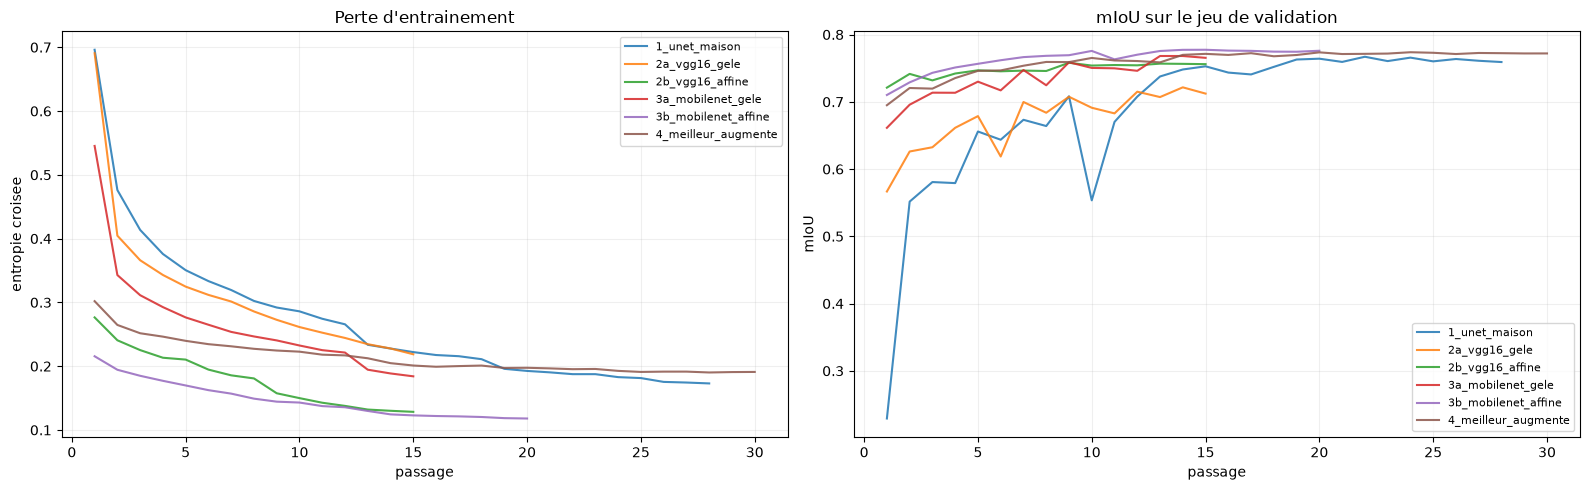

In [38]:
# Les courbes d'apprentissage. Ce qu'on regarde :
#  - le mIoU de validation monte-t-il encore a la fin, ou a-t-il plafonne ?
#  - l'ecart entre entrainement et validation se creuse-t-il ? Si oui, le modele
#    commence a memoriser les images plutot qu'a comprendre les scenes.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for nom, r in resultats.items():
    h = r["historique"]
    passages = range(1, len(h["loss"]) + 1)
    axes[0].plot(passages, h["loss"], label=nom, alpha=.85)
    axes[1].plot(passages, h["val_miou"], label=nom, alpha=.85)

axes[0].set_title("Perte d'entrainement")
axes[0].set_xlabel("passage")
axes[0].set_ylabel("entropie croisee")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=.2)

axes[1].set_title("mIoU sur le jeu de validation")
axes[1].set_xlabel("passage")
axes[1].set_ylabel("mIoU")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.2)

plt.tight_layout()
plt.show()

In [39]:
# L'ecart entre entrainement et validation, modele par modele. C'est le
# thermometre du surapprentissage : s'il se creuse, le modele apprend les
# images par coeur au lieu de comprendre les scenes.
print(f"{'modele':22s} | {'mIoU train':>10s} | {'mIoU val':>9s} | {'ecart':>7s}")
print("-" * 56)
for nom, r in resultats.items():
    h = r["historique"]
    meilleur = int(np.argmax(h["val_miou"]))     # le passage retenu
    train, val = h["miou"][meilleur], h["val_miou"][meilleur]
    print(f"{nom:22s} | {train:10.4f} | {val:9.4f} | {train - val:+7.4f}")

modele                 | mIoU train |  mIoU val |   ecart
--------------------------------------------------------
1_unet_maison          |     0.7947 |    0.7670 | +0.0277
2a_vgg16_gele          |     0.7510 |    0.7215 | +0.0294
2b_vgg16_affine        |     0.8082 |    0.7581 | +0.0501
3a_mobilenet_gele      |     0.7971 |    0.7681 | +0.0290
3b_mobilenet_affine    |     0.8463 |    0.7774 | +0.0689
4_meilleur_augmente    |     0.7908 |    0.7737 | +0.0170


In [40]:
# Le gain du transfert d'apprentissage, chiffre
reference = resultats["1_unet_maison"]["meilleur_miou_val"]
print(f"U-Net entraine depuis zero : {reference:.4f}\n")

for nom in ("2b_vgg16_affine", "3b_mobilenet_affine"):
    if nom in resultats:
        score = resultats[nom]["meilleur_miou_val"]
        ecart = score - reference
        print(f"{nom:22s} : {score:.4f}  ({ecart:+.4f} soit {ecart / reference * 100:+.1f} %)")

print("\nApport de l'affinage apres la phase gelee :")
for gele, affine in (("2a_vgg16_gele", "2b_vgg16_affine"),
                     ("3a_mobilenet_gele", "3b_mobilenet_affine")):
    if gele in resultats and affine in resultats:
        a, b = resultats[gele]["meilleur_miou_val"], resultats[affine]["meilleur_miou_val"]
        print(f"  {gele:22s} {a:.4f} -> {affine:22s} {b:.4f}  ({b - a:+.4f})")

U-Net entraine depuis zero : 0.7670

2b_vgg16_affine        : 0.7581  (-0.0090 soit -1.2 %)
3b_mobilenet_affine    : 0.7774  (+0.0104 soit +1.4 %)

Apport de l'affinage apres la phase gelee :
  2a_vgg16_gele          0.7215 -> 2b_vgg16_affine        0.7581  (+0.0365)
  3a_mobilenet_gele      0.7681 -> 3b_mobilenet_affine    0.7774  (+0.0093)


---
# 11. L'apport de l'augmentation de donnees

## Ce qu'on cherche a obtenir

Augmenter les donnees, c'est montrer au modele des variantes deformees des memes images
pour qu'il apprenne ce qui compte vraiment plutot que les details de chaque photo. Avec
2503 images seulement, c'est le levier le plus direct contre le surapprentissage.

Le generateur ecrit plus haut applique les transformations a la volee, differemment a
chaque passage. Le modele ne voit donc jamais deux fois exactement la meme image, ce qui
revient a disposer d'un jeu de donnees bien plus large.

## Le choix des transformations

Il n'est pas anodin, et chacune se justifie par le cas d'usage :

- **Symetrie horizontale.** Une rue vue en miroir reste une rue plausible. Double
  virtuellement le jeu pour un cout nul.
- **Luminosite et contraste.** Le vehicule roulera par temps couvert, en plein soleil, au
  crepuscule. C'est la variation la plus pertinente ici.
- **Decalages, zooms et rotations legeres.** La camera ne sera jamais exactement au meme
  endroit ni parfaitement horizontale.

Deux transformations sont volontairement exclues. La **symetrie verticale**, parce qu'une
rue a l'envers n'existe pas : on apprendrait au modele une situation qu'il ne rencontrera
jamais, en gaspillant de la capacite. Et les **rotations importantes**, pour la meme
raison, l'horizon reste horizontal.

Point critique deja souligne : la transformation geometrique doit s'appliquer exactement
de la meme facon a la photo et a son masque. Si on retourne la photo sans retourner le
masque, on apprend au modele que la route est a droite alors qu'elle est a gauche, et rien
ne le signale.

In [41]:
# On reentraine le meilleur modele SANS augmentation, avec exactement la meme
# recette (memes poids de depart, meme pas d'apprentissage), en ajoutant
# seulement l'augmentation. Le nombre maximal de passages est plus eleve : en
# montrant des variantes deformees, l'augmentation ralentit l'apprentissage, et
# lui accorder le meme plafond la desavantagerait mecaniquement. L'arret anticipe
# coupe de toute facon quand le score ne progresse plus.
sans_augmentation = [r for r in resultats.values() if not r.get("augmentation")]
classement = sorted(sans_augmentation, key=lambda r: -r["meilleur_miou_val"])
MEILLEUR_SANS_AUG = classement[0]["nom"]
print(f"meilleur modele sans augmentation : {MEILLEUR_SANS_AUG} "
      f"({classement[0]['meilleur_miou_val']:.4f})")

CONSTRUCTEURS = {
    "1_unet_maison": lambda: unet_maison(),
    "2a_vgg16_gele": lambda: unet_pretraine("vgg16", geler_encodeur=True),
    "2b_vgg16_affine": lambda: unet_pretraine("vgg16", geler_encodeur=False),
    "3a_mobilenet_gele": lambda: unet_pretraine("mobilenetv2", geler_encodeur=True),
    "3b_mobilenet_affine": lambda: unet_pretraine("mobilenetv2", geler_encodeur=False),
}

# la recette d'origine de chaque modele : (pas d'apprentissage, poids de depart)
RECETTES = {
    "1_unet_maison": (1e-3, None),
    "2a_vgg16_gele": (1e-3, None),
    "2b_vgg16_affine": (1e-4, "2a_vgg16_gele"),
    "3a_mobilenet_gele": (1e-3, None),
    "3b_mobilenet_affine": (1e-4, "3a_mobilenet_gele"),
}
taux, depart = RECETTES[MEILLEUR_SANS_AUG]

r_aug = entrainer(
    "4_meilleur_augmente",
    CONSTRUCTEURS[MEILLEUR_SANS_AUG],
    epoques=45,
    taux=taux,
    poids_depart=depart,
    augmentation=AUGMENTATION,
)

meilleur modele sans augmentation : 3b_mobilenet_affine (0.7774)
[4_meilleur_augmente] recharge | mIoU validation 0.7737 | 30 passages | 65.6 min


In [42]:
# Rechargement complet, le modele augmente compris
resultats = {}
for f in sorted(SORTIES.glob("*_historique.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    resultats[r["nom"]] = r

sans = resultats[MEILLEUR_SANS_AUG]["meilleur_miou_val"]
avec = resultats["4_meilleur_augmente"]["meilleur_miou_val"]

print(f"{MEILLEUR_SANS_AUG:22s} sans augmentation : {sans:.4f}")
print(f"{'4_meilleur_augmente':22s} avec augmentation : {avec:.4f}")
print(f"{'':22s} ecart             : {avec - sans:+.4f} "
      f"({(avec - sans) / sans * 100:+.1f} %)")
print()
print("Attention a la lecture : cet ecart est mesure sur le jeu de validation, qui")
print("compte 472 images. Sa significativite est evaluee plus loin, sur le jeu de test,")
print("par reechantillonnage. Un ecart plus petit que le bruit de mesure n'est pas un")
print("resultat exploitable.")

3b_mobilenet_affine    sans augmentation : 0.7774
4_meilleur_augmente    avec augmentation : 0.7737
                       ecart             : -0.0037 (-0.5 %)

Attention a la lecture : cet ecart est mesure sur le jeu de validation, qui
compte 472 images. Sa significativite est evaluee plus loin, sur le jeu de test,
par reechantillonnage. Un ecart plus petit que le bruit de mesure n'est pas un
resultat exploitable.


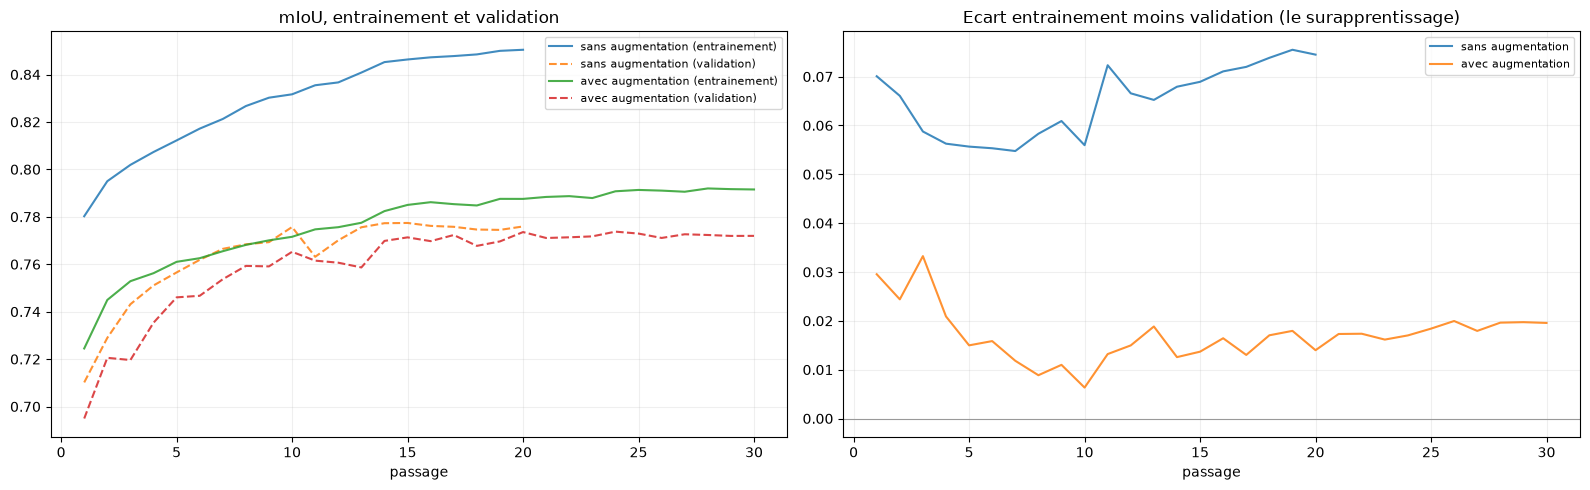

In [43]:
# Les courbes des deux versions, cote a cote. Ce qu'on regarde : l'augmentation
# doit reduire l'ecart entre entrainement et validation, meme si elle fait
# parfois baisser legerement le score d'entrainement.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for nom, etiquette in ((MEILLEUR_SANS_AUG, "sans augmentation"),
                       ("4_meilleur_augmente", "avec augmentation")):
    h = resultats[nom]["historique"]
    passages = range(1, len(h["loss"]) + 1)
    axes[0].plot(passages, h["miou"], label=f"{etiquette} (entrainement)", alpha=.85)
    axes[0].plot(passages, h["val_miou"], "--", label=f"{etiquette} (validation)", alpha=.85)
    axes[1].plot(passages, [t - v for t, v in zip(h["miou"], h["val_miou"])],
                 label=etiquette, alpha=.85)

axes[0].set_title("mIoU, entrainement et validation")
axes[0].set_xlabel("passage")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=.2)

axes[1].axhline(0, color="#999", lw=.8)
axes[1].set_title("Ecart entrainement moins validation (le surapprentissage)")
axes[1].set_xlabel("passage")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.2)

plt.tight_layout()
plt.show()

In [44]:
# Diagnostic : l'entrainement augmente avait-il fini de converger ?
# Si son meilleur passage etait le dernier, il montait encore quand on l'a coupe,
# et conclure a l'absence de gain serait une erreur.
print(f"{'modele':24s} | {'meilleur passage':>16s} | {'sur':>4s} | {'verdict'}")
print("-" * 76)
for nom in (MEILLEUR_SANS_AUG, "4_meilleur_augmente"):
    h = resultats[nom]["historique"]
    meilleur = int(np.argmax(h["val_miou"])) + 1
    total = len(h["val_miou"])
    verdict = ("montait encore quand on l'a arrete"
               if meilleur == total else f"avait plafonne {total - meilleur} passages avant la fin")
    print(f"{nom:24s} | {meilleur:16d} | {total:4d} | {verdict}")

# L'ecart entre le score d'entrainement et celui de validation, au passage
# retenu, mesure le surapprentissage : plus il est grand, plus le modele a
# appris ses images par coeur au lieu de comprendre les scenes.
print("\nSurapprentissage, au passage retenu :")
for nom in (MEILLEUR_SANS_AUG, "4_meilleur_augmente"):
    h = resultats[nom]["historique"]
    k = int(np.argmax(h["val_miou"]))
    print(f"  {nom:24s} mIoU train {h['miou'][k]:.4f} | val {h['val_miou'][k]:.4f} | "
          f"ecart {h['miou'][k] - h['val_miou'][k]:+.4f}")

print("\nBruit de mesure, pour situer les ecarts :")
for nom in (MEILLEUR_SANS_AUG, "4_meilleur_augmente"):
    # on ecarte les premiers passages, encore domines par la montee initiale
    v = np.array(resultats[nom]["historique"]["val_miou"][5:])
    print(f"  {nom:24s} ecart-type du mIoU val d'un passage a l'autre : {v.std():.4f}")

modele                   | meilleur passage |  sur | verdict
----------------------------------------------------------------------------
3b_mobilenet_affine      |               15 |   20 | avait plafonne 5 passages avant la fin
4_meilleur_augmente      |               24 |   30 | avait plafonne 6 passages avant la fin

Surapprentissage, au passage retenu :
  3b_mobilenet_affine      mIoU train 0.8463 | val 0.7774 | ecart +0.0689
  4_meilleur_augmente      mIoU train 0.7908 | val 0.7737 | ecart +0.0170

Bruit de mesure, pour situer les ecarts :
  3b_mobilenet_affine      ecart-type du mIoU val d'un passage a l'autre : 0.0050
  4_meilleur_augmente      ecart-type du mIoU val d'un passage a l'autre : 0.0070


## Lecture du resultat

Trois constats, a ne pas melanger.

**Le modele augmente a eu toute la place necessaire.** On lui a accorde jusqu'a 45
passages, et l'arret anticipe l'a coupe de lui-meme apres qu'il a plafonne (cellule
ci-dessus). La comparaison n'est donc pas faussee par un entrainement trop court.

**Sur le score, pas de difference exploitable.** L'ecart de mIoU de validation est du
meme ordre que la variation du score d'un passage au suivant. La section suivante le
verifie sur le jeu de test, par reechantillonnage.

**Sur le surapprentissage, l'effet est net.** L'ecart entre le score d'entrainement et
celui de validation est nettement plus faible avec augmentation (cellule ci-dessus) : le
modele apprend beaucoup moins ses images par coeur.

Comment concilier les deux : avec un encodeur deja entraine sur un million d'images et
l'arret anticipe qui retient le meilleur passage, le modele sans augmentation etait deja
protege du surapprentissage au moment ou on le choisit. L'augmentation le rend plus
robuste, mais ce gain ne se voit pas sur un jeu de test qui ressemble beaucoup au jeu
d'entrainement : memes cameras, meme pays, memes conditions de prise de vue. On peut
penser qu'elle compterait davantage face a des situations jamais vues, la nuit ou sous la
pluie, mais Cityscapes ne permet pas de le mesurer, donc je ne l'affirme pas.

Pour le projet : le modele retenu reste celui qui a le meilleur score de validation. Ici
c'est la version sans augmentation, et la section suivante montre que l'ecart avec la
version augmentee n'est pas significatif.

---
# 12. Evaluation finale sur le jeu de test

## La regle du jeu de test

Jusqu'ici, toutes les decisions ont ete prises sur le jeu de validation : le choix de
l'architecture, le moment d'arreter, la reduction du pas d'apprentissage, l'apport de
l'augmentation. Les 500 images de test n'ont jamais ete ouvertes.

C'est la seule facon d'obtenir une mesure honnete. Des qu'on regarde le jeu de test pour
prendre une decision, meme une seule, il cesse d'etre un jeu de test : on commence, sans le
vouloir, a choisir ce qui marche bien dessus, et le score annonce devient optimiste.

On l'ouvre donc maintenant, une seule fois, quand plus aucune decision ne reste a prendre.

## Mesurer l'incertitude, pas seulement le score

Annoncer qu'un modele obtient 0,78 et un autre 0,77 ne veut rien dire si la marge d'erreur
de la mesure est de 0,02. Un ecart plus petit que le bruit n'est pas un resultat, et il ne
faut pas aller le defendre devant un jury.

Pour chiffrer cette incertitude, on utilise le **reechantillonnage**. Le principe : nos 500
images sont un echantillon parmi d'autres possibles. Si on avait filme 500 autres rues, le
score aurait ete un peu different. Pour estimer de combien, on tire au hasard 500 images
parmi nos 500, avec remise, donc certaines sortent plusieurs fois et d'autres pas du tout.
On recalcule le score sur ce tirage, et on recommence mille fois. La dispersion des mille
scores obtenus donne la marge d'erreur.

Pour que ce soit realisable, on stocke la matrice de confusion de **chaque image**
separement, et non une seule matrice globale. On peut alors recomposer le score de
n'importe quel tirage en additionnant les matrices correspondantes, sans jamais relancer
le modele.

## Comparer deux modeles proprement

Pour comparer deux modeles, on fait le tirage sur les **memes images** pour les deux a la
fois. C'est important : une partie de la variabilite vient simplement du fait que certaines
rues sont plus faciles a segmenter que d'autres. En leur faisant subir le meme tirage,
cette part disparait et il ne reste que la difference attribuable aux modeles.

In [45]:
# Le classement est celui du jeu de VALIDATION : c'est lui qui decide, pas le
# jeu de test. On note aussi le deuxieme, uniquement pour mesurer plus loin si
# l'ecart entre les deux premiers est reel ou s'il tient au hasard.
CONSTRUCTEURS["4_meilleur_augmente"] = CONSTRUCTEURS[MEILLEUR_SANS_AUG]

classement = sorted(resultats.values(), key=lambda r: -r["meilleur_miou_val"])
MEILLEUR = classement[0]["nom"]
SECOND = classement[1]["nom"]

print(f"choisi sur la validation : {MEILLEUR} ({classement[0]['meilleur_miou_val']:.4f})")
print(f"deuxieme                 : {SECOND} ({classement[1]['meilleur_miou_val']:.4f})")

choisi sur la validation : 3b_mobilenet_affine (0.7774)
deuxieme                 : 4_meilleur_augmente (0.7737)


In [46]:
def matrices_par_image(modele, jeu="test", taille_lot=TAILLE_LOT):
    """Rend une matrice de confusion 8x8 par image du jeu.

    Stocker le detail par image, plutot qu'une matrice globale, permet ensuite
    de recomposer le score de n'importe quel sous-ensemble sans relancer le
    modele. C'est ce qui rend le reechantillonnage abordable.
    """
    X = np.load(chemins_cache[jeu][0], mmap_mode="r")
    Y = np.load(chemins_cache[jeu][1], mmap_mode="r")

    matrices = np.zeros((len(X), NB_CLASSES, NB_CLASSES), dtype=np.int64)

    t0 = time.perf_counter()
    for debut in range(0, len(X), taille_lot):
        fin = min(debut + taille_lot, len(X))
        images = np.asarray(X[debut:fin], dtype=np.float32) / 255.0

        predictions = modele.predict(images, verbose=0).argmax(axis=-1)
        reels = np.asarray(Y[debut:fin])

        for k in range(fin - debut):
            codes = reels[k].ravel() * NB_CLASSES + predictions[k].ravel()
            comptes = np.bincount(codes, minlength=NB_CLASSES ** 2)
            matrices[debut + k] = comptes.reshape(NB_CLASSES, NB_CLASSES)

    print(f"  {len(X)} images evaluees en {time.perf_counter() - t0:.0f}s")
    return matrices


def miou_depuis_matrices(matrices):
    """Calcule le mIoU global et l'IoU de chaque categorie.

    On additionne d'abord toutes les matrices, puis on calcule les IoU. C'est la
    convention de Cityscapes, et c'est plus juste que de moyenner des IoU
    calcules image par image : une categorie absente d'une image ne vient pas
    perturber la moyenne.
    """
    totale = matrices.sum(axis=0)
    vrais_positifs = np.diag(totale)
    union = totale.sum(axis=1) + totale.sum(axis=0) - vrais_positifs

    ious = np.divide(vrais_positifs, union, out=np.full(NB_CLASSES, np.nan),
                     where=union > 0)
    return np.nanmean(ious), ious

In [47]:
# On charge le modele retenu et on ouvre le jeu de test. Une seule fois.
keras.utils.set_random_seed(GRAINE)

modele_final = CONSTRUCTEURS[MEILLEUR]()
modele_final.load_weights(SORTIES / f"{MEILLEUR}.weights.h5")
print(f"modele evalue : {MEILLEUR} ({modele_final.count_params():,} parametres)")

matrices_test = matrices_par_image(modele_final, "test")
miou_test, ious_test = miou_depuis_matrices(matrices_test)

print(f"\nmIoU sur le jeu de test : {miou_test:.4f}")
print(f"(pour memoire, sur la validation : {resultats[MEILLEUR]['meilleur_miou_val']:.4f})\n")

for nom, iou in sorted(zip(NOMS, ious_test), key=lambda x: -x[1]):
    print(f"  {nom:13s} {iou:.4f}  {'#' * int(iou * 40)}")

C:\Users\wytsd\AppData\Local\Temp\ipykernel_5204\3074582355.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  encodeur = constructeur(include_top=False, weights="imagenet", input_tensor=x)


modele evalue : 3b_mobilenet_affine (3,613,832 parametres)


  500 images evaluees en 14s

mIoU sur le jeu de test : 0.7599
(pour memoire, sur la validation : 0.7774)

  flat          0.9265  #####################################
  sky           0.9024  ####################################
  nature        0.8700  ##################################
  vehicle       0.8425  #################################
  construction  0.8214  ################################
  void          0.6698  ##########################
  human         0.6187  ########################
  object        0.4279  #################


In [48]:
def reechantillonner(matrices, tirages=1000, graine=GRAINE):
    """Estime la marge d'erreur du mIoU par reechantillonnage.

    On tire au hasard autant d'images qu'il y en a, avec remise, on recalcule le
    score, et on recommence. La dispersion des scores obtenus donne
    l'incertitude de la mesure.
    """
    rng = np.random.default_rng(graine)
    n = len(matrices)
    scores = np.empty(tirages)
    for t in range(tirages):
        scores[t] = miou_depuis_matrices(matrices[rng.integers(0, n, size=n)])[0]
    return scores


t0 = time.perf_counter()
scores = reechantillonner(matrices_test)
bas, haut = np.percentile(scores, [2.5, 97.5])

print(f"{len(scores)} tirages en {time.perf_counter() - t0:.0f}s\n")
print(f"mIoU sur le jeu de test : {miou_test:.4f}")
print(f"intervalle a 95 %       : [{bas:.4f}, {haut:.4f}]")
print(f"marge d'erreur          : plus ou moins {(haut - bas) / 2:.4f}")
print(f"ecart-type              : {scores.std():.4f}")
print(f"\nAutrement dit : tout ecart de moins de {(haut - bas) / 2:.3f} entre deux")
print("modeles n'est pas distinguable du bruit de mesure sur 500 images.")

1000 tirages en 0s

mIoU sur le jeu de test : 0.7599
intervalle a 95 %       : [0.7520, 0.7677]
marge d'erreur          : plus ou moins 0.0079
ecart-type              : 0.0040

Autrement dit : tout ecart de moins de 0.008 entre deux
modeles n'est pas distinguable du bruit de mesure sur 500 images.


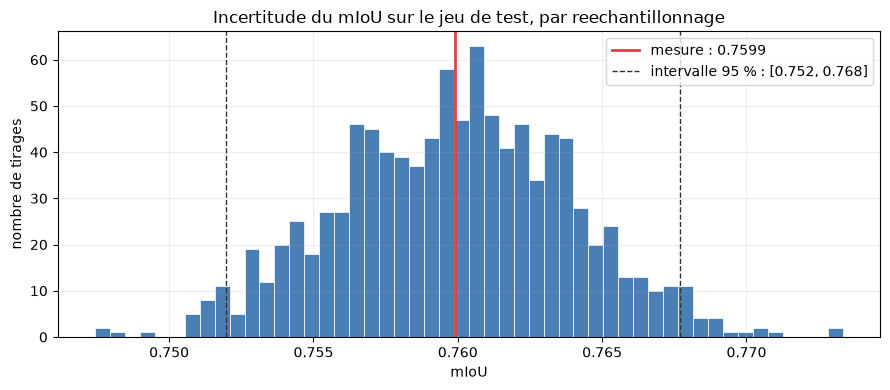

In [49]:
# La distribution des scores reechantillonnes, pour visualiser l'incertitude
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(scores, bins=50, color="#4a7fb5", edgecolor="white", linewidth=.5)
ax.axvline(miou_test, color="#d64545", lw=2, label=f"mesure : {miou_test:.4f}")
ax.axvline(bas, color="#333", ls="--", lw=1, label=f"intervalle 95 % : [{bas:.3f}, {haut:.3f}]")
ax.axvline(haut, color="#333", ls="--", lw=1)
ax.set_xlabel("mIoU")
ax.set_ylabel("nombre de tirages")
ax.set_title("Incertitude du mIoU sur le jeu de test, par reechantillonnage")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## Comparer les deux meilleurs modeles

On evalue aussi le deuxieme du classement sur le jeu de test, uniquement pour savoir si
l'ecart entre les deux est reel ou s'il tient au hasard de l'echantillon. Ce n'est pas une
decision : le choix du modele a deja ete fait sur la validation, et on ne le changera pas
selon ce resultat.

In [50]:
keras.utils.set_random_seed(GRAINE)
modele_second = CONSTRUCTEURS[SECOND]()
modele_second.load_weights(SORTIES / f"{SECOND}.weights.h5")
matrices_second = matrices_par_image(modele_second, "test")

miou_second, _ = miou_depuis_matrices(matrices_second)
print(f"\n{MEILLEUR:22s} : {miou_test:.4f}")
print(f"{SECOND:22s} : {miou_second:.4f}")
print(f"{'ecart brut':22s} : {miou_test - miou_second:+.4f}")

C:\Users\wytsd\AppData\Local\Temp\ipykernel_5204\3074582355.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  encodeur = constructeur(include_top=False, weights="imagenet", input_tensor=x)


  500 images evaluees en 11s

3b_mobilenet_affine    : 0.7599
4_meilleur_augmente    : 0.7590
ecart brut             : +0.0009


In [51]:
def comparer_apparie(matrices_a, matrices_b, tirages=1000, graine=GRAINE):
    """Compare deux modeles sur les memes tirages d'images.

    Faire subir aux deux modeles exactement le meme tirage elimine la part de
    variabilite qui vient de la difficulte des images, et ne garde que la
    difference attribuable aux modeles eux-memes.
    """
    rng = np.random.default_rng(graine)
    n = len(matrices_a)
    ecarts = np.empty(tirages)
    for t in range(tirages):
        indices = rng.integers(0, n, size=n)      # le meme tirage pour les deux
        ecarts[t] = (miou_depuis_matrices(matrices_a[indices])[0]
                     - miou_depuis_matrices(matrices_b[indices])[0])
    return ecarts


ecarts = comparer_apparie(matrices_test, matrices_second)
bas_e, haut_e = np.percentile(ecarts, [2.5, 97.5])

print(f"ecart moyen        : {ecarts.mean():+.4f}")
print(f"intervalle a 95 %  : [{bas_e:+.4f}, {haut_e:+.4f}]")
print(f"{MEILLEUR} devant dans {(ecarts > 0).mean() * 100:.1f} % des tirages\n")

if bas_e > 0:
    print(f"L'ecart est significatif : {MEILLEUR} est devant dans la quasi-totalite des")
    print("tirages, et l'intervalle de confiance ne contient pas zero.")
elif haut_e < 0:
    print(f"L'ecart est significatif, mais dans l'autre sens : {SECOND} est meilleur.")
else:
    print("L'ecart n'est PAS significatif : l'intervalle contient zero, donc on ne peut")
    print("pas conclure que l'un des deux modeles est meilleur que l'autre sur ce jeu de")
    print("test. Le depart doit alors se faire sur d'autres criteres : taille du modele,")
    print("vitesse d'inference, simplicite de mise en production.")

ecart moyen        : +0.0009
intervalle a 95 %  : [-0.0010, +0.0026]
3b_mobilenet_affine devant dans 84.0 % des tirages

L'ecart n'est PAS significatif : l'intervalle contient zero, donc on ne peut
pas conclure que l'un des deux modeles est meilleur que l'autre sur ce jeu de
test. Le depart doit alors se faire sur d'autres criteres : taille du modele,
vitesse d'inference, simplicite de mise en production.


## Ou le modele se trompe-t-il ?

La matrice de confusion montre, pour chaque categorie reelle, dans quelles categories le
modele a range ses pixels. La diagonale represente les bonnes reponses, tout ce qui est a
cote est une confusion.

C'est plus informatif qu'un score global : confondre du trottoir avec de la route est
genant, confondre un pieton avec un vehicule l'est beaucoup plus.

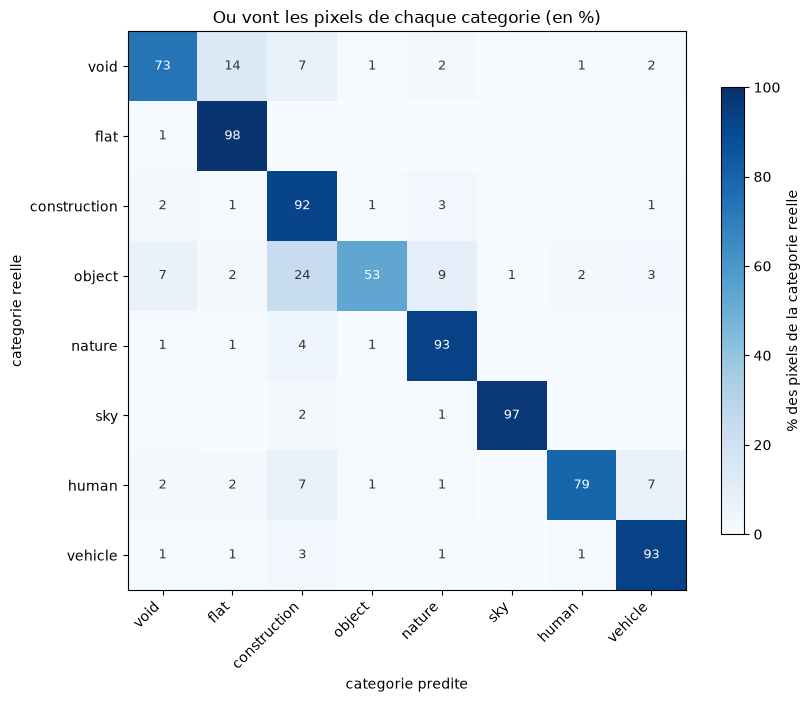

In [52]:
totale = matrices_test.sum(axis=0)

# on normalise par ligne : chaque ligne montre ou sont partis les pixels d'une
# categorie reelle, en pourcentage
normalisee = totale / np.maximum(totale.sum(axis=1, keepdims=True), 1) * 100

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(normalisee, cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(NB_CLASSES), NOMS, rotation=45, ha="right")
ax.set_yticks(range(NB_CLASSES), NOMS)
ax.set_xlabel("categorie predite")
ax.set_ylabel("categorie reelle")
ax.set_title("Ou vont les pixels de chaque categorie (en %)")

for i in range(NB_CLASSES):
    for j in range(NB_CLASSES):
        if normalisee[i, j] >= 0.5:
            ax.text(j, i, f"{normalisee[i, j]:.0f}", ha="center", va="center",
                    color="white" if normalisee[i, j] > 50 else "#333", fontsize=9)

plt.colorbar(image, ax=ax, shrink=.8, label="% des pixels de la categorie reelle")
plt.tight_layout()
plt.show()

In [53]:
# Les confusions les plus frequentes, en clair
confusions = [(normalisee[i, j], NOMS[i], NOMS[j])
              for i in range(NB_CLASSES) for j in range(NB_CLASSES)
              if i != j and normalisee[i, j] >= 1.0]

print("Confusions au-dessus de 1 % des pixels de la categorie :\n")
for part, reel, predit in sorted(confusions, reverse=True)[:12]:
    print(f"  {part:5.1f} %  des pixels {reel:13s} sont predits {predit}")

Confusions au-dessus de 1 % des pixels de la categorie :

   23.6 %  des pixels object        sont predits construction
   13.6 %  des pixels void          sont predits flat
    9.0 %  des pixels object        sont predits nature
    7.4 %  des pixels void          sont predits construction
    7.3 %  des pixels human         sont predits construction
    6.9 %  des pixels object        sont predits void
    6.8 %  des pixels human         sont predits vehicle
    3.9 %  des pixels nature        sont predits construction
    2.8 %  des pixels vehicle       sont predits construction
    2.6 %  des pixels construction  sont predits nature
    2.6 %  des pixels object        sont predits vehicle
    2.0 %  des pixels object        sont predits human


## Une confusion qui vient du decoupage en categories

Deux confusions dominent : des objets fins pris pour des batiments, et du `void` pris pour
de la chaussee (`flat`). La seconde merite un examen, parce que `void` regroupe des classes
fines tres differentes : le capot du vehicule, les bords de l'image, les objets non
identifies, mais aussi `ground`, le sol qui n'est ni une route ni un trottoir, comme les
paves d'une rue pietonne.

On regarde donc, parmi les pixels annotes `void` et predits `flat`, de quelle classe fine
il s'agit reellement, en relisant les masques d'origine a 34 classes.

In [54]:
# Les masques d'origine a 34 classes, dans le meme ordre que le cache de test
NOMS_FINS = {0: "unlabeled", 1: "ego vehicle", 2: "rectification border",
             3: "out of roi", 4: "static", 5: "dynamic", 6: "ground"}

X = np.load(chemins_cache["test"][0], mmap_mode="r")
Y = np.load(chemins_cache["test"][1], mmap_mode="r")

confondus = np.zeros(34, dtype=np.int64)      # void predit flat, par classe fine
void_par_classe = np.zeros(34, dtype=np.int64)

for debut in range(0, len(X), TAILLE_LOT):
    fin = min(debut + TAILLE_LOT, len(X))
    lot = np.asarray(X[debut:fin], dtype=np.float32) / 255.0
    predits = modele_final.predict(lot, verbose=0).argmax(-1)
    for k in range(fin - debut):
        _, chemin_masque = test[debut + k]
        fins = cv2.resize(cv2.imread(str(chemin_masque), cv2.IMREAD_GRAYSCALE),
                          (LARGEUR, HAUTEUR), interpolation=cv2.INTER_NEAREST)
        est_void = np.asarray(Y[debut + k]) == 0
        void_par_classe += np.bincount(fins[est_void], minlength=34)
        confondus += np.bincount(fins[est_void & (predits[k] == 1)], minlength=34)

total = confondus.sum()
print(f"pixels annotes void et predits flat : {total:,}\n")
for id_fin in np.argsort(-confondus):
    if confondus[id_fin] == 0:
        break
    print(f"  {NOMS_FINS.get(int(id_fin), '?'):22s} {confondus[id_fin] / total * 100:5.1f} % de ces pixels"
          f" | {confondus[id_fin] / void_par_classe[id_fin] * 100:5.1f} % de la classe predite flat")

pixels annotes void et predits flat : 1,082,415

  ground                  92.5 % de ces pixels |  85.8 % de la classe predite flat
  ego vehicle              3.4 % de ces pixels |   1.2 % de la classe predite flat
  static                   3.0 % de ces pixels |   3.3 % de la classe predite flat
  dynamic                  1.0 % de ces pixels |   4.1 % de la classe predite flat
  rectification border     0.1 % de ces pixels |   0.1 % de la classe predite flat
  unlabeled                0.0 % de ces pixels |   0.2 % de la classe predite flat


La reponse est nette : l'essentiel de cette confusion porte sur la classe `ground`, et le
modele range la grande majorite des pixels `ground` dans la chaussee. Il a appris que des
paves au sol ressemblent a une route, ce qui se defend : pour un vehicule, c'est une
surface plane et praticable. C'est le regroupement officiel de Cityscapes qui classe ce sol
dans `void`.

Consequence pour la lecture des resultats : une partie du score perdu sur `void` vient du
decoupage en categories, pas d'une erreur grossiere du modele. Les deux images les moins
bien segmentees, plus bas, sont d'ailleurs des rues pietonnes pavees. Pour le systeme de
decision, la vraie question serait plutot de savoir si `ground` doit etre traite comme une
surface roulable, un choix a discuter avec Laura.

## Le cout a l'inference, critere clef pour l'embarque

Un modele destine a un vehicule doit tenir dans un calculateur embarque et repondre assez
vite pour que le systeme de decision reagisse. Le score seul ne suffit donc pas a trancher :
on mesure aussi le temps de prediction et la taille du modele.

Attention a la lecture : les temps ci-dessous sont mesures sur une carte graphique de
bureau. Un calculateur embarque est bien plus lent. Ces chiffres servent a **comparer les
modeles entre eux**, pas a promettre une performance en conditions reelles.

In [55]:
X = np.load(chemins_cache["test"][0], mmap_mode="r")
lot_essai = np.asarray(X[:8], dtype=np.float32) / 255.0

print(f"{'modele':22s} | {'parametres':>11s} | {'poids Mo':>8s} | {'ms/image':>9s}")
print("-" * 60)

for nom in resultats:
    fichier = SORTIES / f"{nom}.weights.h5"
    if not fichier.exists():
        continue

    keras.utils.set_random_seed(GRAINE)
    modele = CONSTRUCTEURS[nom]()
    modele.load_weights(fichier)

    modele.predict(lot_essai, verbose=0)      # mise en route, non comptee
    torch.cuda.synchronize()                  # sinon on mesure le lancement, pas le calcul

    t0 = time.perf_counter()
    for _ in range(10):
        modele.predict(lot_essai, verbose=0)
    torch.cuda.synchronize()
    par_image = (time.perf_counter() - t0) / 10 / len(lot_essai)

    print(f"{nom:22s} | {modele.count_params():11,d} | "
          f"{fichier.stat().st_size / 1024**2:7.1f} | {par_image * 1000:8.1f}")

    del modele
    torch.cuda.empty_cache()

modele                 |  parametres | poids Mo |  ms/image
------------------------------------------------------------


1_unet_maison          |   7,769,160 |    89.1 |     19.5


2a_vgg16_gele          |  18,549,032 |   100.2 |     32.0


2b_vgg16_affine        |  18,549,032 |   212.4 |     32.2


C:\Users\wytsd\AppData\Local\Temp\ipykernel_5204\3074582355.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  encodeur = constructeur(include_top=False, weights="imagenet", input_tensor=x)


3a_mobilenet_gele      |   3,613,832 |    37.1 |     17.9


3b_mobilenet_affine    |   3,613,832 |    41.7 |     18.0


4_meilleur_augmente    |   3,613,832 |    41.7 |     17.9


## Regarder les resultats

Un score ne dit pas tout. On regarde des predictions, y compris celles ou le modele
echoue : c'est la qu'on comprend ses limites, et c'est ce qu'un jury demandera.

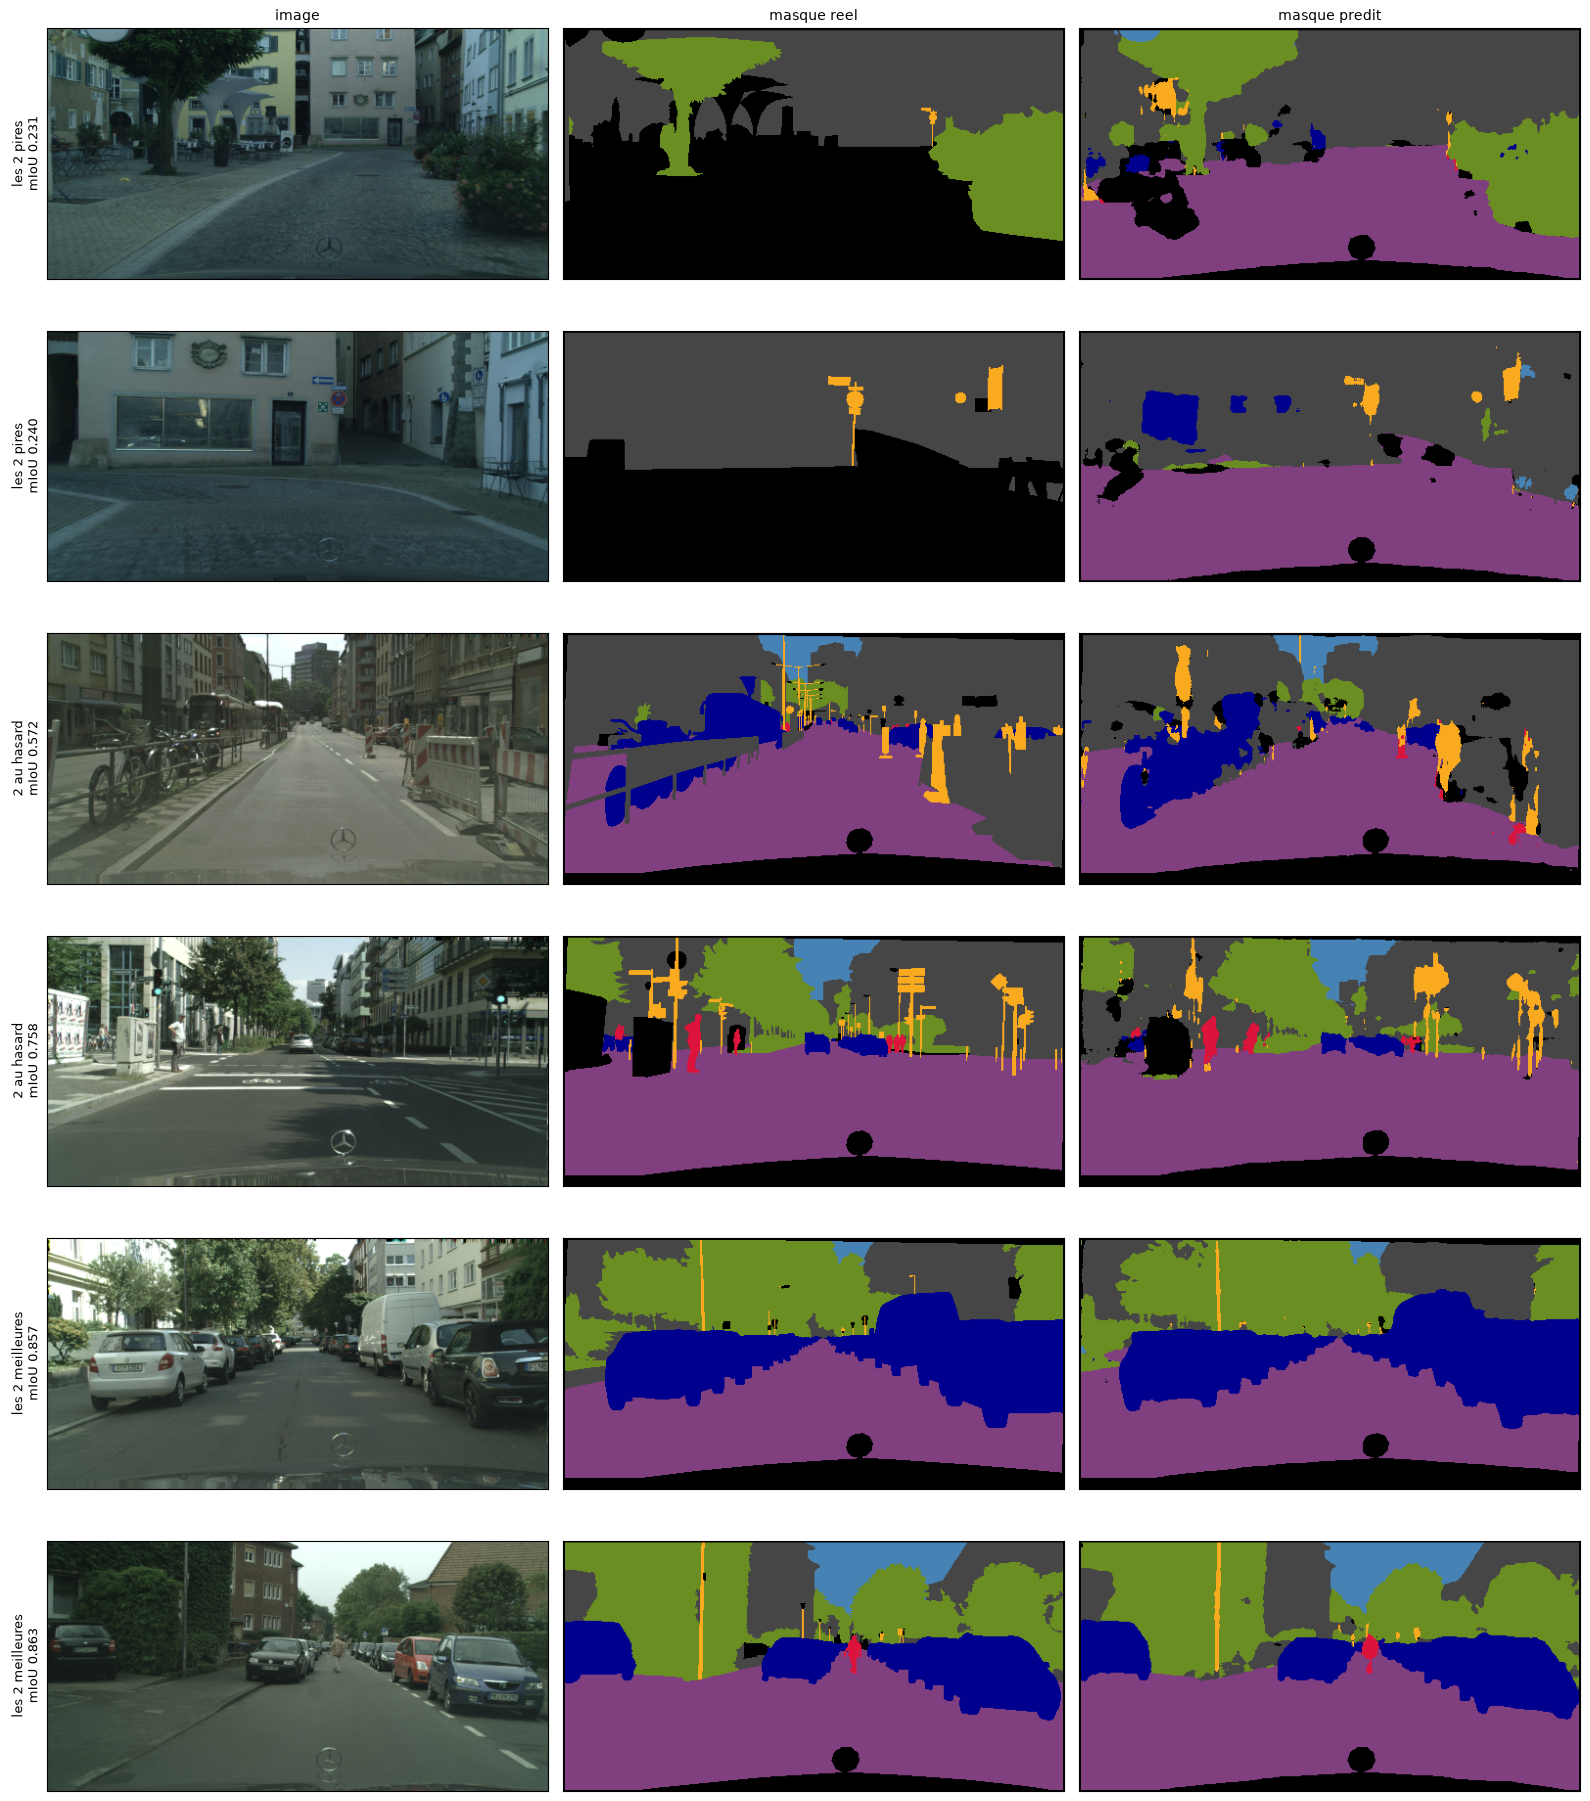

In [56]:
# On choisit des exemples representatifs : les deux pires, deux au hasard, et
# les deux meilleures. Ne montrer que les reussites serait malhonnete.
scores_images = np.array([miou_depuis_matrices(m[None])[0] for m in matrices_test])
ordre = np.argsort(scores_images)

rng_choix = np.random.default_rng(GRAINE)
selection = (list(ordre[:2])
             + list(rng_choix.choice(ordre[2:-2], 2, replace=False))
             + list(ordre[-2:]))
titres = ["les 2 pires"] * 2 + ["2 au hasard"] * 2 + ["les 2 meilleures"] * 2

X = np.load(chemins_cache["test"][0], mmap_mode="r")
Y = np.load(chemins_cache["test"][1], mmap_mode="r")

fig, axes = plt.subplots(len(selection), 3, figsize=(16, 3.1 * len(selection)))
for ligne, (indice, titre) in enumerate(zip(selection, titres)):
    image = np.asarray(X[indice], dtype=np.float32)[None] / 255.0
    predit = modele_final.predict(image, verbose=0)[0].argmax(-1)

    axes[ligne, 0].imshow(X[indice])
    axes[ligne, 0].set_ylabel(f"{titre}\nmIoU {scores_images[indice]:.3f}", fontsize=9)
    axes[ligne, 1].imshow(PALETTE[np.asarray(Y[indice])])
    axes[ligne, 2].imshow(PALETTE[predit])

    for colonne in range(3):
        axes[ligne, colonne].set_xticks([])
        axes[ligne, colonne].set_yticks([])

axes[0, 0].set_title("image", fontsize=10)
axes[0, 1].set_title("masque reel", fontsize=10)
axes[0, 2].set_title("masque predit", fontsize=10)
plt.tight_layout()
plt.show()

In [57]:
# On fige le resultat final dans un fichier, qui servira a configurer l'API et
# a renseigner la note technique sans avoir a rejouer le notebook.
bilan = {
    "modele_retenu": MEILLEUR,
    "miou_validation": resultats[MEILLEUR]["meilleur_miou_val"],
    "miou_test": float(miou_test),
    "intervalle_95": [float(bas), float(haut)],
    "marge_erreur": float((haut - bas) / 2),
    "iou_par_categorie": {nom: float(v) for nom, v in zip(NOMS, ious_test)},
    "parametres": resultats[MEILLEUR]["parametres"],
    "taille_image": {"largeur": LARGEUR, "hauteur": HAUTEUR},
    "graine": GRAINE,
}
(SORTIES / "bilan_final.json").write_text(json.dumps(bilan, indent=2), encoding="utf-8")
print(json.dumps(bilan, indent=2))

{
  "modele_retenu": "3b_mobilenet_affine",
  "miou_validation": 0.7774038910865784,
  "miou_test": 0.7598993574983688,
  "intervalle_95": [
    0.7519796568689688,
    0.7676898685542805
  ],
  "marge_erreur": 0.007855105842655807,
  "iou_par_categorie": {
    "void": 0.6698434545863589,
    "flat": 0.9264857186394241,
    "construction": 0.8213763875045449,
    "object": 0.4278987240947849,
    "nature": 0.8699771832400232,
    "sky": 0.9024272628124557,
    "human": 0.6186777975745732,
    "vehicle": 0.842508331534786
  },
  "parametres": 3613832,
  "taille_image": {
    "largeur": 512,
    "hauteur": 256
  },
  "graine": 42
}


---
# 13. Export du modele pour la mise en production

## Le probleme

L'API doit tourner sur un hebergement gratuit, sans carte graphique, et les offres
gratuites limitent la memoire, a 512 Mo pour celle retenue. Or servir le modele avec
Keras et PyTorch demande bien plus, comme le mesure la cellule plus bas.

## La solution : ONNX

ONNX est un format standard qui decrit uniquement les calculs d'un reseau deja entraine,
sans tout l'outillage d'entrainement. On le fait tourner avec ONNX Runtime, une
bibliotheque concue seulement pour predire, et bien plus legere. C'est ce qui se fait sur
les vrais systemes embarques : on entraine avec un outil complet, on deploie avec un
moteur d'inference leger.

Le modele reste entraine avec Keras, comme le demande l'equipe. ONNX n'intervient
qu'apres, pour le service. Et comme le pretraitement des images fait partie du modele, il
est exporte avec lui : l'API n'a rien a reproduire.

## La condition

Cet export n'a de sens que si le modele exporte donne les memes resultats que celui qui
vient d'etre evalue. On le verifie sur les 500 images du jeu de test.

In [58]:
import warnings

import onnxruntime as ort

API = Path("Wyts_Dimitri_2_API_092026")
FICHIER_ONNX = API / "modele_entraine" / "segmentation.onnx"
FICHIER_ONNX.parent.mkdir(exist_ok=True)

# Keras n'exporte qu'un modele deja appele une fois, c'est le cas : il vient
# d'evaluer le jeu de test. Les avertissements du traceur de PyTorch sont
# masques : ils signalent que certaines tailles sont figees, ce qui est voulu
# ici puisque l'API envoie toujours des images de 512x256.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modele_final.export(str(FICHIER_ONNX), format="onnx")
print(f"modele exporte : {FICHIER_ONNX} ({FICHIER_ONNX.stat().st_size / 2**20:.1f} Mo)")


def session_onnx(chemin, coeurs=4, reserve=True):
    """Ouvre un modele ONNX avec ONNX Runtime, sur processeur."""
    options = ort.SessionOptions()
    options.intra_op_num_threads = coeurs
    options.inter_op_num_threads = 1
    options.enable_cpu_mem_arena = reserve
    return ort.InferenceSession(str(chemin), options, providers=["CPUExecutionProvider"])


session = session_onnx(FICHIER_ONNX)
entree = session.get_inputs()[0]
print(f"entree : {entree.shape} {entree.type} | sortie : {session.get_outputs()[0].shape}")

Saved artifact at 'Wyts_Dimitri_2_API_092026\modele_entraine\segmentation.onnx'.


modele exporte : Wyts_Dimitri_2_API_092026\modele_entraine\segmentation.onnx (13.8 Mo)
entree : ['batch', 256, 512, 3] tensor(float) | sortie : ['Softmax3848_dim_0', 256, 512, 8]


In [59]:
# Equivalence : le modele exporte, sur processeur, donne-t-il les memes masques que
# le modele Keras evalue plus haut, sur la carte graphique ?
X = np.load(chemins_cache["test"][0], mmap_mode="r")
Y = np.load(chemins_cache["test"][1], mmap_mode="r")

matrices_onnx = np.zeros_like(matrices_test)
identiques = total_pixels = 0
ecart_max = 0.0

for debut in range(0, len(X), TAILLE_LOT):
    fin = min(debut + TAILLE_LOT, len(X))
    lot = np.asarray(X[debut:fin], dtype=np.float32) / 255.0

    p_keras = modele_final.predict(lot, verbose=0)
    p_onnx = session.run(None, {entree.name: lot})[0]

    ecart_max = max(ecart_max, float(np.abs(p_keras - p_onnx).max()))
    a_keras, a_onnx = p_keras.argmax(-1), p_onnx.argmax(-1)
    identiques += int((a_keras == a_onnx).sum())
    total_pixels += a_keras.size

    reels = np.asarray(Y[debut:fin])
    for k in range(fin - debut):
        codes = reels[k].ravel() * NB_CLASSES + a_onnx[k].ravel()
        matrices_onnx[debut + k] = np.bincount(
            codes, minlength=NB_CLASSES ** 2).reshape(NB_CLASSES, NB_CLASSES)

miou_onnx, _ = miou_depuis_matrices(matrices_onnx)
print(f"images comparees             : {len(X)}")
print(f"pixels de meme categorie     : {identiques / total_pixels * 100:.4f} % "
      f"({total_pixels - identiques} pixels differents sur {total_pixels:,})")
print(f"ecart maximal de probabilite : {ecart_max:.1e}")
print(f"mIoU test, Keras             : {miou_test:.4f}")
print(f"mIoU test, ONNX              : {miou_onnx:.4f}")

images comparees             : 500
pixels de meme categorie     : 99.9847 % (10051 pixels differents sur 65,536,000)
ecart maximal de probabilite : 2.9e-02
mIoU test, Keras             : 0.7599
mIoU test, ONNX              : 0.7599


In [60]:
import subprocess
import sys
import tempfile


def dans_un_processus_neuf(code_source, variables=None):
    """Execute du code dans un processus Python neuf et rend ce qu'il affiche.

    Indispensable pour mesurer la memoire : le processus du notebook a deja
    charge Keras, PyTorch et des gigaoctets de donnees, sa memoire ne dirait
    rien de ce que consomme l'API.
    """
    env = dict(os.environ, **(variables or {}))
    r = subprocess.run([sys.executable, "-c", code_source],
                       capture_output=True, text=True, env=env, timeout=900)
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-1500:])
    return r.stdout.strip().splitlines()[-1]


# La memoire est relevee apres dix predictions, comme une API qui a deja servi.
MESURE = """
import psutil, time, numpy as np
p = psutil.Process()
x = np.random.rand(1, 256, 512, 3).astype("float32")
{charger}
for _ in range(3):
    predire(x)
t0 = time.perf_counter()
for _ in range(10):
    predire(x)
print(round(p.memory_info().rss / 2**20), round((time.perf_counter() - t0) / 10 * 1000))
"""

with tempfile.TemporaryDirectory() as dossier:
    # pour Keras, on sauvegarde le modele complet dans un dossier temporaire
    chemin_keras = Path(dossier) / "modele.keras"
    modele_final.save(chemin_keras)

    resultats_service = {
        "Keras + PyTorch": dans_un_processus_neuf(
            MESURE.format(charger=f"""
import torch, keras
torch.set_num_threads(1)
m = keras.saving.load_model(r"{chemin_keras}", compile=False)
def predire(x): m.predict(x, verbose=0)
"""),
            {"CUDA_VISIBLE_DEVICES": "-1", "KERAS_BACKEND": "torch"}),
    }

for reserve in (True, False):
    nom = "ONNX Runtime, reserve " + ("activee" if reserve else "desactivee")
    resultats_service[nom] = dans_un_processus_neuf(MESURE.format(charger=f"""
import onnxruntime as ort
o = ort.SessionOptions()
o.intra_op_num_threads = 1
o.inter_op_num_threads = 1
o.enable_cpu_mem_arena = {reserve}
s = ort.InferenceSession(r"{FICHIER_ONNX.resolve()}", o, providers=["CPUExecutionProvider"])
nom = s.get_inputs()[0].name
def predire(x): s.run(None, {{nom: x}})
"""))

print("Servir le modele sur processeur, 1 coeur, sans carte graphique :\n")
print(f"{'moteur':36s} | {'memoire':>8s} | {'par image':>9s}")
print("-" * 60)
for nom, ligne in resultats_service.items():
    memoire, ms = ligne.split()
    print(f"{nom:36s} | {memoire:>5s} Mo | {ms:>6s} ms")

Servir le modele sur processeur, 1 coeur, sans carte graphique :

moteur                               |  memoire | par image
------------------------------------------------------------
Keras + PyTorch                      |  1191 Mo |    512 ms
ONNX Runtime, reserve activee        |   191 Mo |    313 ms
ONNX Runtime, reserve desactivee     |    79 Mo |    328 ms


## Lecture du resultat

**L'export est equivalent.** Le mIoU sur le jeu de test est identique a quatre
decimales. Les quelques pixels qui different sont des cas ou deux categories avaient des
probabilites presque egales, et ou un arrondi de calcul a fait pencher la balance : la
carte graphique calcule avec une precision legerement reduite pour aller plus vite, le
processeur non. Sur plus de 65 millions de pixels, c'est sans effet sur le score.

**Le gain en memoire est massif.** Servir le modele avec Keras et PyTorch depasse
largement les 512 Mo de l'hebergement gratuit, ONNX Runtime tient tres en dessous, et il
predit meme plus vite sur un coeur.

**La reserve de memoire d'ONNX Runtime** est une zone qu'il garde pour eviter de
redemander de la memoire a chaque calcul. La desactiver ralentit tres legerement la
prediction mais divise encore la memoire occupee. Sur un hebergement limite a 512 Mo,
c'est le bon compromis, et c'est le reglage retenu dans l'API.

La cellule suivante ecrit la configuration de l'API a partir des resultats de ce
notebook. Le fichier ONNX et cette configuration sont exactement ce qui est deploye.

In [61]:
# On ecrit la configuration de l'API a partir des resultats mesures ci-dessus,
# plutot que de recopier des chiffres a la main.
ARCHITECTURES = {
    "1_unet_maison": "unet_maison",
    "2a_vgg16_gele": "vgg16", "2b_vgg16_affine": "vgg16",
    "3a_mobilenet_gele": "mobilenetv2", "3b_mobilenet_affine": "mobilenetv2",
    "4_meilleur_augmente": "mobilenetv2",
}

config_api = {
    "architecture": ARCHITECTURES[MEILLEUR],
    "modele": "modele_entraine/segmentation.onnx",
    "modele_source": MEILLEUR,
    "parametres": int(modele_final.count_params()),
    "miou_test": round(float(miou_test), 4),
    "miou_test_intervalle_95": [round(float(bas), 4), round(float(haut), 4)],
    "iou_par_categorie": {nom: round(float(v), 4) for nom, v in zip(NOMS, ious_test)},
}
(API / "config.json").write_text(json.dumps(config_api, indent=2), encoding="utf-8")
print(json.dumps(config_api, indent=2))

{
  "architecture": "mobilenetv2",
  "modele": "modele_entraine/segmentation.onnx",
  "modele_source": "3b_mobilenet_affine",
  "parametres": 3613832,
  "miou_test": 0.7599,
  "miou_test_intervalle_95": [
    0.752,
    0.7677
  ],
  "iou_par_categorie": {
    "void": 0.6698,
    "flat": 0.9265,
    "construction": 0.8214,
    "object": 0.4279,
    "nature": 0.87,
    "sky": 0.9024,
    "human": 0.6187,
    "vehicle": 0.8425
  }
}
